NAME:ADWAIT MANOJ DATIR

ZEPTO STORE-PRODUCT-CUSTOMER-ANALYSIS

Loading of the given dataset

In [1]:
import pandas as pd
payments = pd.read_csv('Payments_Information.csv')
products = pd.read_csv('Products_Information.csv')
promotions = pd.read_csv('Promotions_Information.csv')
sales = pd.read_csv('Sales_Data.csv')
stores = pd.read_csv('Stores_Information.csv')
customers = pd.read_csv('Customers_Information.csv')
pd.set_option('display.float_format', '{:,.2f}'.format)


basic operations on the whole dataset along with forming joins so that based on it can get the basic info of how the data looks like

checking for any null values within all files

In [2]:
print("payments null values if:\n",payments.isnull().sum())
print("products null values if:\n",products.isnull().sum())
print("payments null values if:\n",payments.isnull().sum())
print("promotions null values if:\n",promotions.isnull().sum())
print("sales null values if:\n",sales.isnull().sum())
print("stores null values if:\n",stores.isnull().sum())
print("customers null values if:\n",customers.isnull().sum())

payments null values if:
 PaymentID        0
PaymentMethod    0
dtype: int64
products null values if:
 ProductID      0
ProductName    0
Category       0
Brand          0
MRP            0
BuyingPrice    0
dtype: int64
payments null values if:
 PaymentID        0
PaymentMethod    0
dtype: int64
promotions null values if:
 Unnamed: 0.1       0
Unnamed: 0         0
PromotionID        0
PromotionType      0
DiscountPercent    0
dtype: int64
sales null values if:
 OrderID             0
OrderDateTime       0
CustomerID          0
ProductID           0
StoreID             0
PaymentID           0
PromotionID         0
Quantity            1
UnitPrice           1
GrossAmount         1
DiscountAmount      1
NetAmount           1
DeliveryMinutes     1
OrderStatus         1
OperationCharges    1
Order_Profit        1
dtype: int64
stores null values if:
 Unnamed: 0        0
StoreID           0
StoreName         0
City              0
OpeningYear       0
Employee_Count    0
dtype: int64
customers null

filling the null values with mean,median and maximum values

In [3]:
x = (sales['Quantity'].median())
y = round(sales['UnitPrice'].mean())
z = round(sales['GrossAmount'].mean())
w = round(sales['OperationCharges'].mean())
a = round(sales['DiscountAmount'].mean())
b = round(sales['NetAmount'].mean())
c = round(sales['DeliveryMinutes'].mean())
d = sales.groupby('OrderStatus')['CustomerID'].count().idxmax()
e = round(sales['Order_Profit'].mean())
sales['Quantity'] = sales['Quantity'].fillna(x)
sales['UnitPrice'] = sales['UnitPrice'].fillna(y)
sales['GrossAmount'] = sales['GrossAmount'].fillna(z)
sales['OperationCharges'] = sales['OperationCharges'].fillna(w)
sales['DiscountAmount'] = sales['DiscountAmount'].fillna(a)
sales['NetAmount'] = sales['NetAmount'].fillna(b)
sales['DeliveryMinutes'] = sales['DeliveryMinutes'].fillna(c)
sales['OrderStatus'] = sales['OrderStatus'].fillna(d)
sales['Order_Profit'] = sales['Order_Profit'].fillna(e)
sales['PaymentID'] = sales['PaymentID'].fillna('123')
sales['ProductID'] = sales['ProductID'].fillna('456')
sales['StoreID'] = sales['StoreID'].fillna('abc123')
sales['PromotionID'] = sales['PromotionID'].fillna('promo123')
#checking all the values
print("payments null values if:\n",payments.isnull().sum())
print("products null values if:\n",products.isnull().sum())
print("payments null values if:\n",payments.isnull().sum())
print("promotions null values if:\n",promotions.isnull().sum())
print("sales null values if:\n",sales.isnull().sum())
print("stores null values if:\n",stores.isnull().sum())
print("customers null values if:\n",customers.isnull().sum())

payments null values if:
 PaymentID        0
PaymentMethod    0
dtype: int64
products null values if:
 ProductID      0
ProductName    0
Category       0
Brand          0
MRP            0
BuyingPrice    0
dtype: int64
payments null values if:
 PaymentID        0
PaymentMethod    0
dtype: int64
promotions null values if:
 Unnamed: 0.1       0
Unnamed: 0         0
PromotionID        0
PromotionType      0
DiscountPercent    0
dtype: int64
sales null values if:
 OrderID             0
OrderDateTime       0
CustomerID          0
ProductID           0
StoreID             0
PaymentID           0
PromotionID         0
Quantity            0
UnitPrice           0
GrossAmount         0
DiscountAmount      0
NetAmount           0
DeliveryMinutes     0
OrderStatus         0
OperationCharges    0
Order_Profit        0
dtype: int64
stores null values if:
 Unnamed: 0        0
StoreID           0
StoreName         0
City              0
OpeningYear       0
Employee_Count    0
dtype: int64
customers null

getting the basic_info about all data


In [4]:
print("payments-info\n",payments.info())
print("products-info\n",products.info())
print("promotions-info\n",promotions.info())
print("sales-info\n",sales.info())
print("Stores-info\n",stores.info())
print("customers-info\n",customers.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   PaymentID      5 non-null      object
 1   PaymentMethod  5 non-null      object
dtypes: object(2)
memory usage: 212.0+ bytes
payments-info
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    2200 non-null   object 
 1   ProductName  2200 non-null   object 
 2   Category     2200 non-null   object 
 3   Brand        2200 non-null   object 
 4   MRP          2200 non-null   float64
 5   BuyingPrice  2200 non-null   float64
dtypes: float64(2), object(4)
memory usage: 103.3+ KB
products-info
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype

converting the datetime column object to datetime

In [5]:
sales['OrderDateTime'] = pd.to_datetime(sales['OrderDateTime'])
stores['OpeningYear'] = pd.to_numeric(stores['OpeningYear'], errors='coerce').astype('Int64')

customers['SignupDate'] = pd.to_datetime(customers['SignupDate'])
customers['FirstOrderDate'] = pd.to_datetime(customers['FirstOrderDate'])

In [6]:
stores['OpeningYear'].head()

,OpeningYear
0,2022
1,2024
2,2023
3,2021
4,2023


checking again for basic info

In [7]:
print("payments-info\n",payments.info())
print("products-info\n",products.info())
print("promotions-info\n",promotions.info())
print("sales-info\n",sales.info())
print("Stores-info\n",stores.info())
print("customers-info\n",customers.info())
print("---"*10)
print("---describe_info---")
print("payments-info\n",payments.describe())
print("products-info\n",products.describe())
print("promotions-info\n",promotions.describe())
print("sales-info\n",sales.describe())
print("Stores-info\n",stores.describe())
print("customers-info\n",customers.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   PaymentID      5 non-null      object
 1   PaymentMethod  5 non-null      object
dtypes: object(2)
memory usage: 212.0+ bytes
payments-info
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    2200 non-null   object 
 1   ProductName  2200 non-null   object 
 2   Category     2200 non-null   object 
 3   Brand        2200 non-null   object 
 4   MRP          2200 non-null   float64
 5   BuyingPrice  2200 non-null   float64
dtypes: float64(2), object(4)
memory usage: 103.3+ KB
products-info
 None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype

Joining all the dataset into a big table

In [8]:
sales_customers = pd.merge(customers,sales,on='CustomerID',how='inner')
sales_products = pd.merge(products,sales,on='ProductID',how='inner')
sales_stores = pd.merge(stores,sales,on='StoreID',how='inner')
sales_payments = pd.merge(payments,sales,on='PaymentID',how='inner')
sales_promotions = pd.merge(promotions,sales,on='PromotionID',how='inner')

final_join = sales.merge(customers[['CustomerID','CustomerName','City','SignupDate','CustomerSegment']], on='CustomerID') \
                  .merge(products[['ProductID','ProductName','Category','Brand','MRP','BuyingPrice']], on='ProductID') \
                  .merge(stores[['StoreID','StoreName','OpeningYear','Employee_Count']], on='StoreID') \
                  .merge(payments[['PaymentID','PaymentMethod']], on='PaymentID') \
                  .merge(promotions[['PromotionID','PromotionType','DiscountPercent']], on='PromotionID',how='inner')

print(final_join)


              OrderID       OrderDateTime      CustomerID       ProductID  \
0       ORDVNR1ANUN3T 2023-07-21 04:37:00  CUSTAKL9HQ0PU7  PROD9ZVRX3UEZ9   
1       ORD86D1R7PLT2 2024-11-08 04:39:00  CUSTFZILYFV63R  PRODLOPWD7N1G1   
2       ORDSOO3N4NJV3 2024-06-17 10:24:00  CUST2X37B97UAC  PRODQ0YT2A4OY8   
3       ORDDMGIJAI3D8 2024-09-16 12:04:00  CUSTMEANOR0EST  PROD3KGD7FD5IZ   
4       ORDFHZ7M9M684 2023-09-15 23:27:00  CUSTHG3ZOZTJ8N  PRODSXEQSX3O74   
...               ...                 ...             ...             ...   
313474  ORDM6M1WVLV80 2024-11-05 17:11:00  CUSTLOKU0MAN5S  PROD67DMHRKQIS   
313475  ORDF4HZ6PCX1M 2024-02-18 00:59:00  CUSTL1JR2K03C4  PROD0A8KQV9PU3   
313476  ORD2CHL18PJC3 2023-07-09 10:59:00  CUSTI6A2THRHVJ  PRODS94WDW6DGX   
313477  ORDTR9JYHZ33I 2023-11-23 11:01:00  CUSTLH81VMCW52  PRODBD9GOTKE4I   
313478  ORDBM3PMJZQFO 2023-02-05 08:05:00  CUSTF5187OZYMU  PROD904XQ5BJBO   

              StoreID      PaymentID      PromotionID  Quantity  UnitPrice 

Q1)What is the distribution of the quantity variable in the dataset?

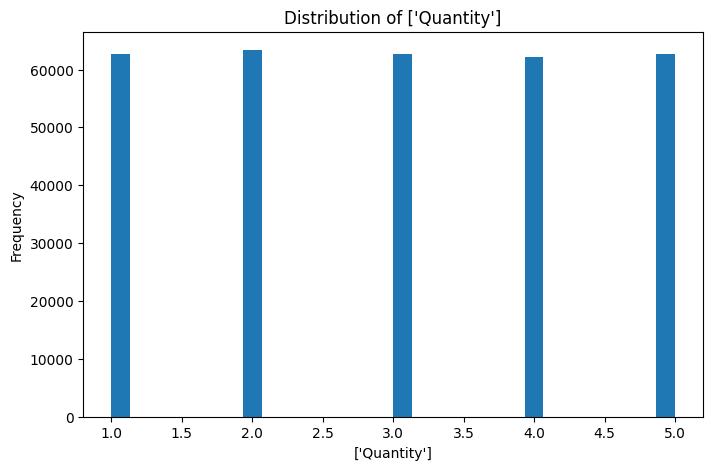

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
data = final_join.copy()

variable = [
    'Quantity'
    ]
for value in variable:
   plt.figure(figsize=(8, 5))
   plt.hist(data[variable], bins=30)
   plt.xlabel(variable)
   plt.ylabel('Frequency')
   plt.title(f'Distribution of {variable}')
   plt.show()


Q2)How do the mean, median, distribution, and outliers vary across Gross Amount, Discount Amount, Net Amount, and Order Profit in the Zepto dataset?


GrossAmount
Mean: 306.04345531917613
Median: 152.25
The mean is higher than the median, indicating a right-skewed distribution.
Q1: 80.0
Q3: 329.96
IQR: 249.95999999999998
Lower Limit: -294.93999999999994
Upper Limit: 704.8999999999999
Number of Outliers: 32906


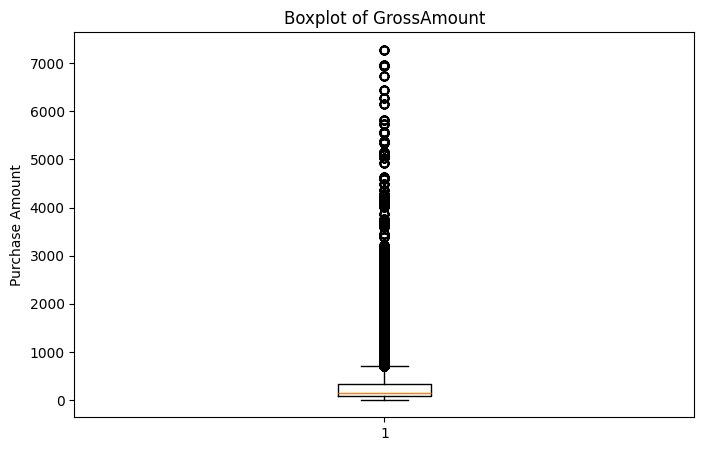


DiscountAmount
Mean: 39.98813174088217
Median: 40.0
The mean is lower than the median, indicating a left-skewed distribution.
Q1: 29.96
Q3: 49.98
IQR: 20.019999999999996
Lower Limit: -0.06999999999999318
Upper Limit: 80.00999999999999
Number of Outliers: 0


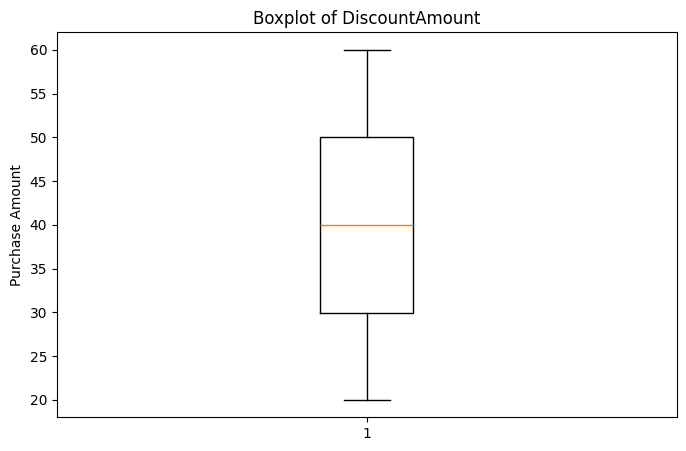


NetAmount
Mean: 252.75255739937927
Median: 106.628
The mean is higher than the median, indicating a right-skewed distribution.
Q1: 36.1475
Q3: 273.00625
IQR: 236.85875000000001
Lower Limit: -319.14062500000006
Upper Limit: 628.2943750000001
Number of Outliers: 33142


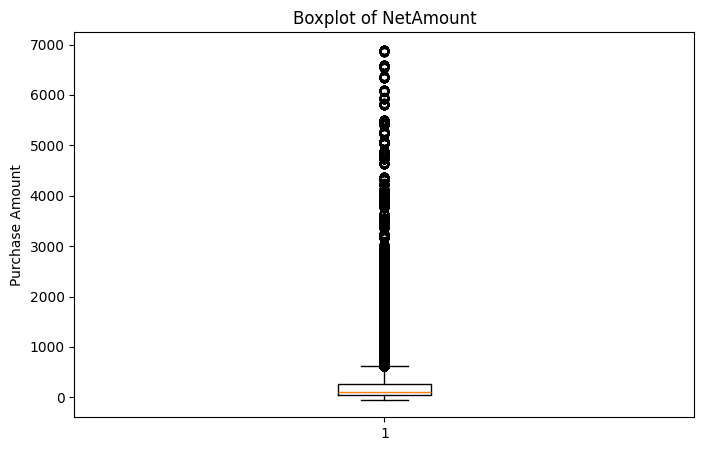


Order_Profit
Mean: 12.305172042157453
Median: 5.187707973235054
The mean is higher than the median, indicating a right-skewed distribution.
Q1: 1.7585071503411576
Q3: 13.28882524599002
IQR: 11.530318095648862
Lower Limit: -15.536969993132134
Upper Limit: 30.58430238946331
Number of Outliers: 33113


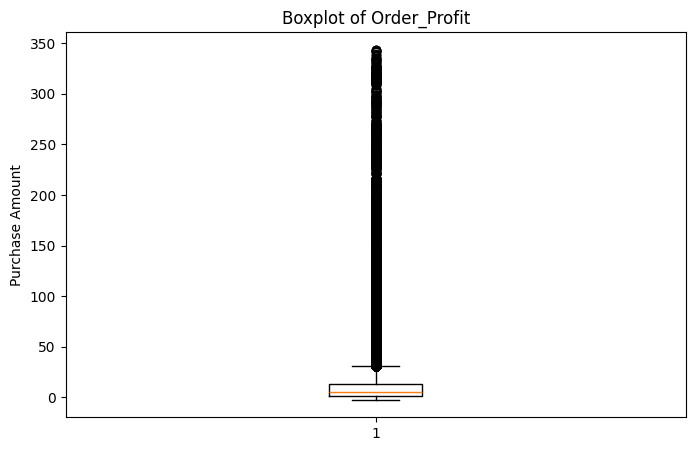

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = final_join.copy()

columns = ['GrossAmount', 'DiscountAmount', 'NetAmount', 'Order_Profit']

for column in columns:

    print("\n" + "="*50)
    print(column)
    print("="*50)

    # Mean and Median
    mean = data[column].mean()
    median = data[column].median()

    print("Mean:", mean)
    print("Median:", median)

    if mean > median:
        print("The mean is higher than the median, indicating a right-skewed distribution.")
    elif mean < median:
        print("The mean is lower than the median, indicating a left-skewed distribution.")
    else:
        print("The mean and median are equal, indicating a relatively symmetric distribution.")

    # IQR and Outliers
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Number of Outliers:", len(outliers))

    # Boxplot
    plt.figure(figsize=(8, 5))
    plt.boxplot(data[column])
    plt.ylabel('Purchase Amount')
    plt.title(f'Boxplot of {column}')
    plt.show()

Q3)What are the total Buying Price, Gross Revenue, Operating Charges, Discount Amount, and Net Amount in the dataset, and how do the remaining expenses and adjustments compare with the final recorded profit?

In [11]:
data = final_join.copy()

buying_price = data['BuyingPrice'].sum() / 100000
gross_amount = data['GrossAmount'].sum() / 100000
operating_amount = data['OperationCharges'].sum() / 100000
discount_amount = data['DiscountAmount'].sum() / 100000
net_amount = data['NetAmount'].sum() / 100000
profit = data['Order_Profit'].sum() / 100000
# Calculate remaining expenses and adjustments
remaining_expenses = net_amount - profit
print(f"Buying Price: {buying_price:,.2f} Lakhs")
print(f"Gross Amount (Revenue): {gross_amount:,.2f} Lakhs")
print(f"Operating Amount: {operating_amount:,.2f} Lakhs")
print(f"Discount Amount: {discount_amount:,.2f} Lakhs")
print(f"Net Amount: {net_amount:,.2f} Lakhs")
print(f"Remaining Expenses/Adjustments: {remaining_expenses:,.2f} Lakhs")
print(f"Final Profit: {profit:,.2f} Lakhs")

Buying Price: 304.46 Lakhs
Gross Amount (Revenue): 959.38 Lakhs
Operating Amount: 41.70 Lakhs
Discount Amount: 125.35 Lakhs
Net Amount: 792.33 Lakhs
Remaining Expenses/Adjustments: 753.75 Lakhs
Final Profit: 38.57 Lakhs


Q4)Analyze the monthly financial performance by grouping the data by year and month. Calculate the total Buying Price, Gross Amount, Operation Charges, Net Amount, and Discount Amount, along with their month-over-month percentage growth rates. Display the results in a table and create four bar plots to visualize the monthly growth in Net Amount, Revenue (Gross Amount), Buying Price (Investment), and Discount Amount.

                             BuyingPrice  investment_growth      Revenue  revenue_growth  Operation_Charges  Operation_Charges_growth   Net_Amount  Net_Growth  Discount_amount  Discount_Amount_Growth
OrderDateTime OrderDateTime                                                                                                                                                                            
2023          1             1,114,231.48                NaN 3,527,345.08             NaN         153,249.05                       NaN 2,911,731.98         NaN       462,364.05                     NaN
              2             1,009,307.80              -9.42 3,159,695.46          -10.42         137,552.55                    -10.24 2,613,498.35      -10.24       408,644.56                  -11.62
              3             1,125,901.58              11.55 3,526,062.62           11.60         153,466.42                     11.57 2,915,862.04       11.57       456,734.16                   11.77


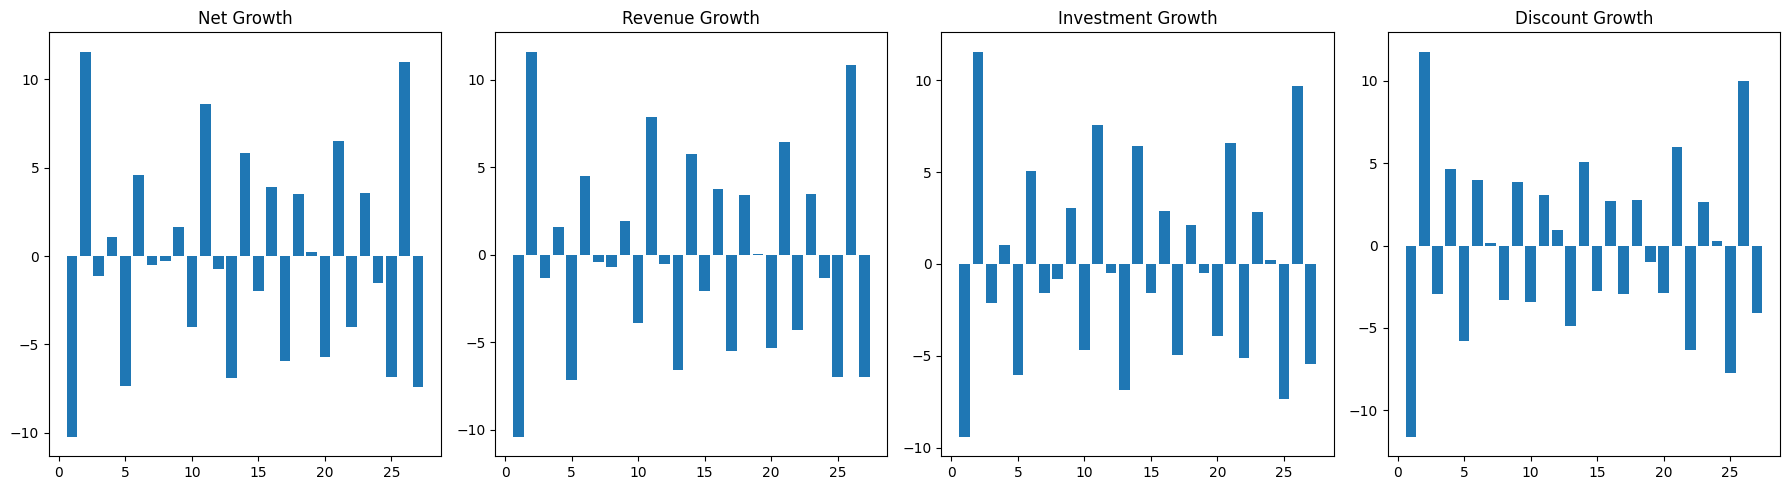

In [12]:
import matplotlib.pyplot as plt

data = final_join.copy()
value1 = data.groupby([
    data['OrderDateTime'].dt.year,
    data['OrderDateTime'].dt.month
])['BuyingPrice'].sum()

value2 = data.groupby(
    [
        data['OrderDateTime'].dt.year,
        data['OrderDateTime'].dt.month
    ])['GrossAmount'].sum()

value3 = data.groupby(
    [
        data['OrderDateTime'].dt.year,
        data['OrderDateTime'].dt.month
    ])['OperationCharges'].sum()

value4 = data.groupby(
    [
        data['OrderDateTime'].dt.year,
        data['OrderDateTime'].dt.month
    ])['NetAmount'].sum()

value5 = data.groupby(
    [
        data['OrderDateTime'].dt.year,
        data['OrderDateTime'].dt.month
    ])['DiscountAmount'].sum()



table = value1.to_frame(name='BuyingPrice')
table['investment_growth'] = value1.pct_change() * 100
table['Revenue'] = value2
table['revenue_growth'] = value2.pct_change() * 100
table['Operation_Charges'] = value3
table['Operation_Charges_growth'] = value3.pct_change()*100
table['Net_Amount'] = value4
table['Net_Growth'] = value4.pct_change()*100
table['Discount_amount'] = value5
table['Discount_Amount_Growth'] = value5.pct_change()*100
print(table.to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].bar(range(len(table)), table['Net_Growth'])
axes[0].set_title('Net Growth')

axes[1].bar(range(len(table)), table['revenue_growth'])
axes[1].set_title('Revenue Growth')

axes[2].bar(range(len(table)), table['investment_growth'])
axes[2].set_title('Investment Growth')

axes[3].bar(range(len(table)), table['Discount_Amount_Growth'])
axes[3].set_title('Discount Growth')

plt.tight_layout()
plt.show()


test

### I). City & Store-wise Analysis

This section covers analysis where City and Store are the primary dimensions.

Examples:
- Customers by store and city
- Sales/performance by store and city
- Payment methods by store and city
- Customer segments by store and city
- Promotion types by store and city
- Store-level profitability

In [13]:
data = sales_customers.copy() #loading the dataset for sales and customers relation


Q1)How do customer count, total gross spending, average delivery time, and average discount amount differ across cities?

In [14]:
city = data.groupby('City')
print("The count per city of customers:\n",city['CustomerID'].count().sort_values(ascending=False))
print("The total amount of spending per city\n",(city['GrossAmount'].sum().sort_values(ascending=False)))
print("The average delivery minutes per city\n",city['DeliveryMinutes'].mean().sort_values(ascending=False))
print("The average discount amount given per city\n",city['DiscountAmount'].mean().sort_values(ascending=False))

The count per city of customers:
 City
Kolkata      35461
Delhi        35412
Chennai      35209
Hyderabad    35074
Pune         34789
Mumbai       34650
Bangalore    34421
Noida        34292
Gurgaon      34172
Name: CustomerID, dtype: int64
The total amount of spending per city
 City
Kolkata     10,961,310.58
Hyderabad   10,847,457.51
Delhi       10,819,490.39
Chennai     10,638,831.45
Mumbai      10,588,929.87
Noida       10,581,796.57
Pune        10,550,504.05
Bangalore   10,533,772.56
Gurgaon     10,416,409.35
Name: GrossAmount, dtype: float64
The average delivery minutes per city
 City
Hyderabad   21.08
Gurgaon     21.02
Mumbai      21.02
Kolkata     21.01
Bangalore   21.01
Noida       21.00
Chennai     20.98
Delhi       20.98
Pune        20.92
Name: DeliveryMinutes, dtype: float64
The average discount amount given per city
 City
Gurgaon     40.11
Mumbai      40.03
Hyderabad   40.01
Pune        40.00
Delhi       39.99
Noida       39.97
Kolkata     39.97
Bangalore   39.95
Chennai   

Q2)How many customers are there in each Customer Segment across different cities?

In [15]:

customer_segment = data.groupby(['CustomerSegment','City'])['CustomerID'].count()
print(customer_segment.sort_index(level='CustomerSegment', ascending=True))

CustomerSegment  City     
Occasional       Bangalore     7166
                 Chennai       7263
                 Delhi         7537
                 Gurgaon       6760
                 Hyderabad     7075
                 Kolkata       6926
                 Mumbai        7456
                 Noida         6881
                 Pune          6567
Premium          Bangalore     6538
                 Chennai       6800
                 Delhi         6968
                 Gurgaon       6956
                 Hyderabad     6778
                 Kolkata       7395
                 Mumbai        6649
                 Noida         6544
                 Pune          7708
Regular          Bangalore    20717
                 Chennai      21146
                 Delhi        20907
                 Gurgaon      20456
                 Hyderabad    21221
                 Kolkata      21140
                 Mumbai       20545
                 Noida        20867
                 Pune         20514
N

Q3)How many stores are there in each city?

In [16]:
print(city['StoreID'].nunique())


City
Bangalore    180
Chennai      180
Delhi        180
Gurgaon      180
Hyderabad    180
Kolkata      180
Mumbai       180
Noida        180
Pune         180
Name: StoreID, dtype: int64


Q4)How many customers does each store have in each city?

In [17]:
city = data.groupby(['City','StoreID'])['CustomerID'].nunique().reset_index(name='CustomerCount').sort_values('CustomerCount',ascending=False)

print(city.to_string())

           City        StoreID  CustomerCount
373       Delhi  STR3EXW9S52LG            235
1065    Kolkata  STRXICBFBJCFO            228
966     Kolkata  STRCMX1HMXQGL            228
379       Delhi  STR470SOQI3C3            227
945     Kolkata  STR9KK0LGYDQZ            226
711     Gurgaon  STRYWEP33XAUK            226
1040    Kolkata  STRQ0P01ZT8U3            225
442       Delhi  STREB1FV9Z7KZ            223
178   Bangalore  STRZWDRLC2NE0            223
334     Chennai  STRUQWGCRI3E7            222
1173     Mumbai  STRHRUKZGDANI            222
1055    Kolkata  STRUU1DS4112T            221
1510       Pune  STRCWH1DDEG5C            221
172   Bangalore  STRYXQJ4S0X2O            220
231     Chennai  STRAWU3AD7DRH            220
809   Hyderabad  STRG1LRU9NS55            220
974     Kolkata  STRD6EEZYZ91Z            220
764   Hyderabad  STR8MKFOUW7CD            219
932     Kolkata  STR68EEKE1RZ9            219
34    Bangalore  STR6R2XVA3E1L            218
504       Delhi  STRRSQLX45IXP    

# Q5)**What is the average delivery time for each store in each city?**

In [18]:

minutes = data.groupby(['City','StoreID'])['DeliveryMinutes'].mean().reset_index(name='DeliveryMinutes')
print("Lowest Average Delivery Time:\n")
print(minutes.sort_values('DeliveryMinutes',ascending=True))
print("\nHighest Average Delivery Time:\n")
print(minutes.sort_values('DeliveryMinutes',ascending=False))

Lowest Average Delivery Time:

           City        StoreID  DeliveryMinutes
1063    Kolkata  STRWP2NB254TW            19.09
1249     Mumbai  STRYE3PC6WC7V            19.12
0     Bangalore  STR0C29ZZE2DD            19.20
455       Delhi  STRI3AHBW1M8S            19.29
855   Hyderabad  STRPAUEK0K92B            19.31
...         ...            ...              ...
1392      Noida  STROS00DPNEGE            22.44
812   Hyderabad  STRHJDLTH801L            22.47
1507       Pune  STRCQGS66QJAF            22.47
801   Hyderabad  STREA418HEHSH            22.48
626     Gurgaon  STREPZ5MPJMHA            22.56

[1620 rows x 3 columns]

Highest Average Delivery Time:

           City        StoreID  DeliveryMinutes
626     Gurgaon  STREPZ5MPJMHA            22.56
801   Hyderabad  STREA418HEHSH            22.48
1507       Pune  STRCQGS66QJAF            22.47
812   Hyderabad  STRHJDLTH801L            22.47
1392      Noida  STROS00DPNEGE            22.44
...         ...            ...              ...

Q6)What are the total Gross Amount, Net Amount, and Discount Amount for each store in each city, based on the highest and lowest Net Amount?

In [19]:
# 1. Combine everything into one single GroupBy statement
city_store_table = data.groupby(['City', 'StoreID'])[['GrossAmount', 'NetAmount', 'DiscountAmount']].sum().reset_index()
# Print the unified table
print("Highest gross,net,discount Amount:\n")
print(city_store_table.sort_values(by='NetAmount', ascending=False))
print("lowest gross,Net,discount Amount:\n")
print(city_store_table.sort_values(by='NetAmount', ascending=True))


Highest gross,net,discount Amount:

           City        StoreID  GrossAmount  NetAmount  DiscountAmount
1377      Noida  STRMK2G05ZNOJ    91,223.63  77,764.09        9,366.69
1065    Kolkata  STRXICBFBJCFO    88,150.92  74,676.55        9,544.03
195     Chennai  STR3J73ASSCCT    84,422.73  72,070.98        8,558.54
1055    Kolkata  STRUU1DS4112T    84,034.50  71,554.27        8,714.22
1563       Pune  STRNPDCYDRUP3    83,564.42  71,428.61        8,376.41
...         ...            ...          ...        ...             ...
1395      Noida  STRPAUEK0K92B    39,077.65  31,387.88        6,037.78
767   Hyderabad  STRA6SOJ2VD4B    40,711.59  31,281.07        7,784.15
285     Chennai  STRJNH0RGABOZ    39,943.33  31,007.33        7,304.04
529       Delhi  STRYE3PC6WC7V    38,548.52  30,833.63        6,092.07
1431      Noida  STRYWEP33XAUK    36,439.24  29,349.62        5,544.90

[1620 rows x 5 columns]
lowest gross,Net,discount Amount:

           City        StoreID  GrossAmount  NetAmou

Q7)Which category is most ordered in each city?

In [20]:
data = final_join.copy()

city_category = data.groupby(['City', 'Category'])['Quantity'].count().reset_index(name='OrderCount')


city_category = city_category.sort_values(['City'])

print(city_category)
data['City'].unique()

          City                Category  OrderCount
0    Bangalore               Beverages        9234
11   Bangalore                  Sweets        1303
10   Bangalore                  Snacks        4962
9    Bangalore  Instant Food / Noodles        1711
7    Bangalore       Health & Wellness        1394
..         ...                     ...         ...
97        Pune                Biscuits        3252
96        Pune               Beverages        9488
106       Pune                  Snacks        4943
100       Pune           Confectionery         310
107       Pune                  Sweets        1314

[108 rows x 3 columns]


array(['Pune', 'Hyderabad', 'Mumbai', 'Noida', 'Bangalore', 'Chennai',
       'Gurgaon', 'Kolkata', 'Delhi'], dtype=object)

Q8)What are the total Gross Amount, Net Amount, and Discount Amount for each category across all cities?

In [21]:
data = final_join.copy()
city_spending = data.groupby(['City', 'Category'])[['GrossAmount','DiscountAmount','NetAmount']].sum().reset_index()
city_spending = city_spending.sort_values(
    ['City', 'NetAmount'],
    ascending=[True, False]
)

print(city_spending.to_string(index=False))

     City                   Category  GrossAmount  DiscountAmount    NetAmount
Bangalore                  Beverages 2,321,120.65      368,298.32 1,855,181.21
Bangalore                    Grocery 1,766,662.05       84,960.19 1,597,616.77
Bangalore          Health & Wellness 1,629,449.08       56,112.52 1,494,669.73
Bangalore                      Dairy 1,339,384.73      292,875.06   994,184.19
Bangalore                     Sweets   951,419.21       52,302.56   854,160.82
Bangalore                     Snacks   927,173.45      197,257.26   693,420.38
Bangalore         Coffee / Beverages   692,649.76       54,222.30   606,506.09
Bangalore     Instant Food / Noodles   465,102.45       68,594.00   376,683.03
Bangalore                   Biscuits   292,683.76      129,311.98   155,203.19
Bangalore               Instant Food    81,488.27       12,280.11    65,747.75
Bangalore Chocolates / Confectionery    55,162.82       47,607.98     7,177.10
Bangalore              Confectionery    11,476.33   

Q9)What are the total Gross Amount, Net Amount, and Discount Amount, along with the average Delivery Time, for each store in each city, including the store’s opening year?

In [22]:
data = final_join.copy()

city_stores_info = data.groupby(
    ['City', 'StoreName', 'OpeningYear']
).agg({
    'GrossAmount': 'sum',
    'NetAmount': 'sum',
    'DiscountAmount': 'sum',
    'DeliveryMinutes': 'mean'
}).reset_index()

city_stores_info = city_stores_info.sort_values(
    ['StoreName', 'NetAmount', 'DeliveryMinutes'],
    ascending=[False, True, False]
)

print(city_stores_info)

           City            StoreName  OpeningYear  GrossAmount  NetAmount  \
899   Hyderabad  Zepto Dark Store 99         2024    48,739.00  38,956.80   
1439      Noida  Zepto Dark Store 99         2024    51,209.74  41,212.65   
719     Gurgaon  Zepto Dark Store 99         2024    54,073.66  44,208.78   
539       Delhi  Zepto Dark Store 99         2024    54,325.07  44,217.73   
359     Chennai  Zepto Dark Store 99         2024    56,408.07  45,965.32   
...         ...                  ...          ...          ...        ...   
1260      Noida   Zepto Dark Store 1         2022    62,540.32  52,212.95   
900     Kolkata   Zepto Dark Store 1         2022    63,334.97  53,469.76   
0     Bangalore   Zepto Dark Store 1         2022    68,714.59  57,849.92   
1440       Pune   Zepto Dark Store 1         2022    71,075.96  59,835.65   
540     Gurgaon   Zepto Dark Store 1         2022    76,717.39  64,568.01   

      DiscountAmount  DeliveryMinutes  
899         7,731.84            21.

Q10)How many orders are placed through each payment method in each city?

In [23]:
data = final_join.copy()
city_payment_info = data.groupby(['City','PaymentMethod'])['OrderID'].count()
city_payment_info = city_payment_info.sort_index(
    level=['City', 'PaymentMethod'],
    ascending=[True, True]
)
print(city_payment_info.to_string)


<bound method Series.to_string of City       PaymentMethod
Bangalore  Cash              1681
           Credit Card       4221
           Debit Card        2655
           UPI              22344
           Wallet            3520
Chennai    Cash              1712
           Credit Card       4142
           Debit Card        2783
           UPI              23169
           Wallet            3403
Delhi      Cash              1746
           Credit Card       4256
           Debit Card        2872
           UPI              22937
           Wallet            3601
Gurgaon    Cash              1717
           Credit Card       4097
           Debit Card        2759
           UPI              22244
           Wallet            3355
Hyderabad  Cash              1693
           Credit Card       4082
           Debit Card        2841
           UPI              23004
           Wallet            3454
Kolkata    Cash              1800
           Credit Card       4211
           Debit Card  

Q11)**How many distinct SKUs are available across each product category in each store and city based on the recorded orders?**

**Note:** The SKU count is based on products appearing in registered orders. Therefore, it represents SKUs that were available/listed and had at least one recorded order at the respective store, rather than the complete inventory of SKUs available at the store.


In [24]:
data = final_join.copy()
city_store = data.groupby(['City','StoreName','Category'])['ProductID'].nunique()
print(city_store.to_string())


City       StoreName             Category                  
Bangalore  Zepto Dark Store 1    Beverages                     38
                                 Biscuits                      15
                                 Chocolates / Confectionery     9
                                 Coffee / Beverages            12
                                 Confectionery                  1
                                 Dairy                         39
                                 Grocery                       15
                                 Health & Wellness              9
                                 Instant Food                   1
                                 Instant Food / Noodles         9
                                 Snacks                        26
                                 Sweets                         9
           Zepto Dark Store 10   Beverages                     50
                                 Biscuits                      13
                

Q12)How many orders are associated with each promotion type in each city?

In [25]:
data = final_join.copy()
city_promotion = data.groupby(['City','PromotionType'])['PromotionID'].count()
city_promotion - city_promotion.sort_index(level=['City','PromotionType'],
                                           ascending=[True,True]
                                           )
pd.set_option('display.float_format', '{:,.2f}'.format)
print(city_promotion.to_string)

<bound method Series.to_string of City       PromotionType
Bangalore  BOGO              7279
           Flat              9811
           Free Delivery     9649
           Percentage        7682
Chennai    BOGO              7275
           Flat              9920
           Free Delivery    10152
           Percentage        7862
Delhi      BOGO              7318
           Flat             10036
           Free Delivery    10102
           Percentage        7956
Gurgaon    BOGO              7104
           Flat              9715
           Free Delivery     9700
           Percentage        7653
Hyderabad  BOGO              7413
           Flat             10082
           Free Delivery     9874
           Percentage        7705
Kolkata    BOGO              7380
           Flat             10041
           Free Delivery    10094
           Percentage        7946
Mumbai     BOGO              7281
           Flat              9785
           Free Delivery     9867
           Percentage  

Q13)How many customers are associated with each customer segment in each store across different cities and also calculate the total number of customers per store?

In [26]:
data = final_join.copy()

cities = data['City'].unique()

for city in cities:

    city_filter = data[data['City'] == city]

    store_name = (
        city_filter
        .groupby(['City', 'StoreName', 'CustomerSegment'])['CustomerID']
        .count()
        .reset_index(name='CustomerCount')
    )

    table = pd.DataFrame()
    previous_store = None

    for store in store_name['StoreName'].unique():

        store_data = store_name[store_name['StoreName'] == store]

        # Add customer segment rows
        table = pd.concat([
            table,
            store_data
        ], ignore_index=True)

        # Calculate total customers for the store
        total_customers = store_data['CustomerCount'].sum()

        # Add total row
        total_row = pd.DataFrame([{
            'City': '',
            'StoreName': f'{store} TOTAL',
            'CustomerSegment': '',
            'CustomerCount': total_customers
        }])

        table = pd.concat([
            table,
            total_row
        ], ignore_index=True)

        # Add separator
        separator = pd.DataFrame([{
            'City': '',
            'StoreName': '--------------------',
            'CustomerSegment': '',
            'CustomerCount': ''
        }])

        table = pd.concat([
            table,
            separator
        ], ignore_index=True)

    print(f"\nCITY: {city}")
    print(table.to_string(index=False))

Streaming output truncated to the last 5000 lines.
Noida       Zepto Dark Store 174      Occasional            43
Noida       Zepto Dark Store 174         Premium            38
Noida       Zepto Dark Store 174         Regular           111
      Zepto Dark Store 174 TOTAL                           192
            --------------------                              
Noida       Zepto Dark Store 175      Occasional            53
Noida       Zepto Dark Store 175         Premium            34
Noida       Zepto Dark Store 175         Regular           135
      Zepto Dark Store 175 TOTAL                           222
            --------------------                              
Noida       Zepto Dark Store 176      Occasional            29
Noida       Zepto Dark Store 176         Premium            32
Noida       Zepto Dark Store 176         Regular           130
      Zepto Dark Store 176 TOTAL                           191
            --------------------                              
Noid

Q14)How many transactions and what is the total gross amount for each payment method in each store across different cities?

In [27]:
data = final_join.copy()

cities = data['City'].unique()

for city in cities:
    city_filter = data[data['City'] == city]

    transaction_type = (
        city_filter
        .groupby(['City', 'StoreName', 'PaymentMethod'])
        .agg(
            TransactionCount=('PaymentID', 'count'),
            TotalGrossAmount=('GrossAmount', 'sum')
        )
    )

    print(transaction_type.to_string())

Streaming output truncated to the last 5000 lines.
      Zepto Dark Store 173 Cash                         10          2,579.78
                           Credit Card                  23         12,774.68
                           Debit Card                   15          5,714.42
                           UPI                         113         42,317.57
                           Wallet                       20          6,154.21
      Zepto Dark Store 174 Cash                         13          2,355.39
                           Credit Card                  16          6,495.73
                           Debit Card                   13          4,044.85
                           UPI                         122         37,789.15
                           Wallet                       28          6,535.88
      Zepto Dark Store 175 Cash                         17          4,687.10
                           Credit Card                  23          7,456.87
                         

Q15)Analyze the total Buying Price, Operation Charges, and Order Profit for each Store across different Customer Segments within each City?

In [28]:
data = final_join.copy()

cities = data['City'].unique()

for city in cities:
    city_filter = data[data['City'] == city]

    store_name = (
        city_filter
        .groupby(['City', 'StoreName', 'CustomerSegment'])[
            ['BuyingPrice', 'OperationCharges', 'Order_Profit']
        ]
        .sum()
        .reset_index()
    )

    table = pd.DataFrame()
    previous_store = None

    for _, row in store_name.iterrows():

        if row['StoreName'] != previous_store:

            separator = pd.DataFrame([{
                'City': '',
                'StoreName': '--------------------',
                'CustomerSegment': '',
                'BuyingPrice': '',
                'OperationCharges': '',
                'Order_Profit': ''
            }])

            table = pd.concat([table, separator], ignore_index=True)

        table = pd.concat([
            table,
            pd.DataFrame([row])
        ], ignore_index=True)

        previous_store = row['StoreName']

    # Make sure the column names/order are visible
    table = table[
        ['City', 'StoreName', 'CustomerSegment',
         'BuyingPrice', 'OperationCharges', 'Order_Profit']
    ]

    print(f"\nCITY: {city}")
    print(table.to_string(index=False))

Streaming output truncated to the last 5000 lines.
Mumbai Zepto Dark Store 111         Premium    3,720.34           558.92       514.63
Mumbai Zepto Dark Store 111         Regular    9,326.98         1,341.46     1,242.06
       --------------------                                                          
Mumbai Zepto Dark Store 112      Occasional    3,513.48           588.92       542.21
Mumbai Zepto Dark Store 112         Premium    2,956.21           427.94       400.48
Mumbai Zepto Dark Store 112         Regular   10,038.95         1,521.43     1,409.09
       --------------------                                                          
Mumbai Zepto Dark Store 113      Occasional    3,135.48           393.05       361.17
Mumbai Zepto Dark Store 113         Premium    3,219.50           384.74       358.08
Mumbai Zepto Dark Store 113         Regular   11,181.36         1,782.43     1,649.41
       --------------------                                                          
Mum

Q16)Analyze the number of orders for each Promotion Type across Stores within each City.

In [29]:
data = final_join.copy()

promotion_orders = (
    data
    .groupby(['City', 'StoreName', 'PromotionType'])['OrderID']
    .count()
    .reset_index(name='OrderCount')
)

print(promotion_orders.to_string(index=False))

     City            StoreName PromotionType  OrderCount
Bangalore   Zepto Dark Store 1          BOGO          44
Bangalore   Zepto Dark Store 1          Flat          59
Bangalore   Zepto Dark Store 1 Free Delivery          62
Bangalore   Zepto Dark Store 1    Percentage          25
Bangalore  Zepto Dark Store 10          BOGO          37
Bangalore  Zepto Dark Store 10          Flat          63
Bangalore  Zepto Dark Store 10 Free Delivery          43
Bangalore  Zepto Dark Store 10    Percentage          38
Bangalore Zepto Dark Store 100          BOGO          37
Bangalore Zepto Dark Store 100          Flat          54
Bangalore Zepto Dark Store 100 Free Delivery          52
Bangalore Zepto Dark Store 100    Percentage          46
Bangalore Zepto Dark Store 101          BOGO          42
Bangalore Zepto Dark Store 101          Flat          52
Bangalore Zepto Dark Store 101 Free Delivery          58
Bangalore Zepto Dark Store 101    Percentage          49
Bangalore Zepto Dark Store 102 

Q17)Identify the top 5 and bottom 5 customers based on the number of orders placed in each city.

In [30]:
data = final_join.copy()
value = data.groupby(['City','CustomerID'])['OrderID'].count()
value = (value.sort_values(ascending=False))
print(value.head(5))
print(value.tail(5))

City       CustomerID    
Hyderabad  CUSTIKG0C6FX4M    29
Gurgaon    CUST2G09LBLS36    28
Chennai    CUSTM8AMN4RALB    28
Gurgaon    CUST0M8902TULY    28
Chennai    CUSTYY50H7E6JE    27
Name: OrderID, dtype: int64
City     CustomerID    
Noida    CUSTFV8XSDXRX2    2
Gurgaon  CUSTRBOKKBNUBS    1
         CUST9N59ZPU955    1
Mumbai   CUSTNWGU9B8INN    1
Gurgaon  CUSTRJS9NPTPR2    1
Name: OrderID, dtype: int64


II)Product & Brand-wise Analysis
This section covers analysis where Product and Brand are the primary dimensions.
Examples:
- Sales by Product and Brand
- Discounts by Product and Brand
- Profit by Product and Brand
- Promotions by Product/Brand
- Product-category performance

In [31]:
data = sales_products.copy()


Q1)Analyze the order status distribution for each brand across different product categories?

In [32]:
brand_wise_order_status = data.groupby(['Brand','Category','OrderStatus'])['OrderID'].count()
pd.set_option('display.float_format', '{:,.2f}'.format)
print(brand_wise_order_status.to_string())

Brand       Category                    OrderStatus
Aashirvaad  Grocery                     Cancelled        240
                                        Delivered       4083
                                        Returned          95
Amul        Beverages                   Cancelled         38
                                        Delivered        573
                                        Returned          14
            Confectionery               Cancelled         21
                                        Delivered        424
                                        Returned          10
            Dairy                       Cancelled       1617
                                        Delivered      30833
                                        Returned         660
            Instant Food                Cancelled         67
                                        Delivered       1092
                                        Returned          23
            Snacks               

Q2)How do discounts impact the revenue generated by each brand across different product categories?

         Brand                    Category   GrossAmount  DiscountAmount     NetAmount
0   Aashirvaad                     Grocery  7,523,942.55      176,752.92  6,979,830.15
3         Amul                       Dairy  5,181,774.31    1,326,384.12  3,662,620.68
1         Amul                   Beverages  1,645,645.08       24,917.49  1,539,691.21
4         Amul                Instant Food    304,631.34       47,244.40    244,517.59
5         Amul                      Snacks    167,442.43       52,203.69    109,476.80
2         Amul               Confectionery     15,318.95       18,415.78     -2,941.99
7    Britannia                      Snacks  2,808,932.74      529,703.41  2,165,267.86
6    Britannia                    Biscuits  2,620,480.04    1,178,473.43  1,369,906.28
8     CocaCola                   Beverages  7,899,367.73    1,489,855.65  6,089,036.48
13       Dabur           Health & Wellness 14,438,564.17      489,893.71 13,251,236.94
12       Dabur                     Grocery 

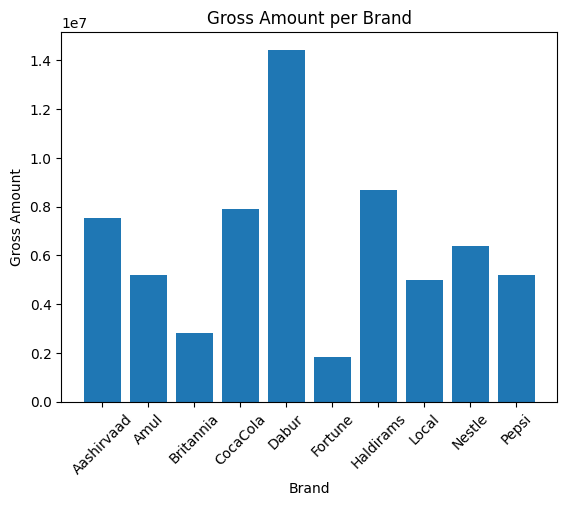

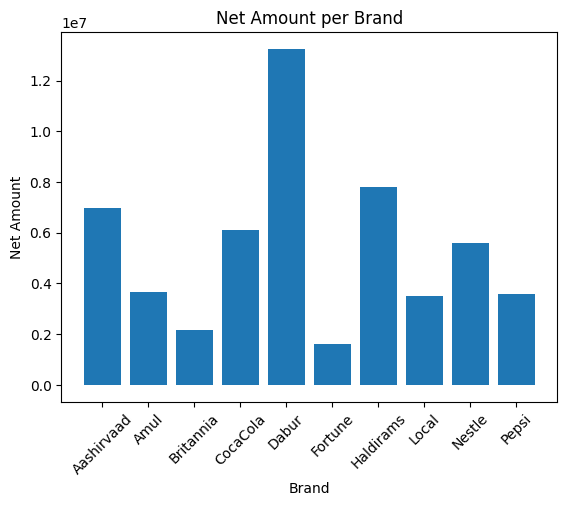

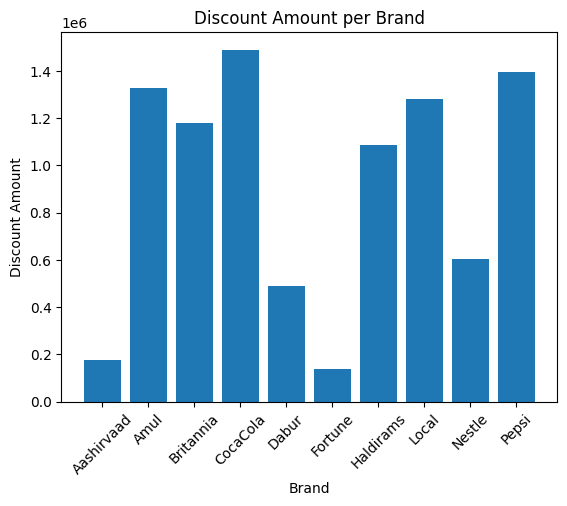

In [33]:
import matplotlib.pyplot as plt

brand_wise_discount_revenue = data.groupby(
    ['Brand', 'Category']
)[['GrossAmount', 'DiscountAmount', 'NetAmount']].sum().reset_index()

brand_wise_discount_revenue = brand_wise_discount_revenue.sort_values(
    ['Brand', 'NetAmount'],
    ascending=[True, False]
)
pd.set_option('display.float_format', '{:,.2f}'.format)
print(brand_wise_discount_revenue.to_string())


# 1. Gross Amount
plt.figure()
plt.bar(
    brand_wise_discount_revenue['Brand'],
    brand_wise_discount_revenue['GrossAmount']
)
plt.xticks(rotation=45)
plt.xlabel('Brand')
plt.ylabel('Gross Amount')
plt.title('Gross Amount per Brand')
plt.show()


# 2. Net Amount
plt.figure()
plt.bar(
    brand_wise_discount_revenue['Brand'],
    brand_wise_discount_revenue['NetAmount']
)
plt.xticks(rotation=45)
plt.xlabel('Brand')
plt.ylabel('Net Amount')
plt.title('Net Amount per Brand')
plt.show()


# 3. Discount Amount
plt.figure()
plt.bar(
    brand_wise_discount_revenue['Brand'],
    brand_wise_discount_revenue['DiscountAmount']
)
plt.xticks(rotation=45)
plt.xlabel('Brand')
plt.ylabel('Discount Amount')
plt.title('Discount Amount per Brand')
plt.show()

Q3)What is the average order value (AOV) for each Brand across different product Categories?

         Brand                    Category      AOV
0   Aashirvaad                     Grocery 1,703.02
2         Amul               Confectionery    33.67
5         Amul                      Snacks   127.62
3         Amul                       Dairy   156.50
4         Amul                Instant Food   257.73
1         Amul                   Beverages 2,633.03
6    Britannia                    Biscuits    88.94
7    Britannia                      Snacks   212.52
8     CocaCola                   Beverages   211.55
10       Dabur               Confectionery    38.45
15       Dabur                      Snacks   123.74
14       Dabur                Instant Food   323.14
9        Dabur                   Beverages   371.75
12       Dabur                     Grocery   570.49
13       Dabur           Health & Wellness 1,178.66
11       Dabur                       Dairy 2,934.20
16     Fortune                     Grocery   517.55
17   Haldirams                      Snacks   186.59
18   Haldira

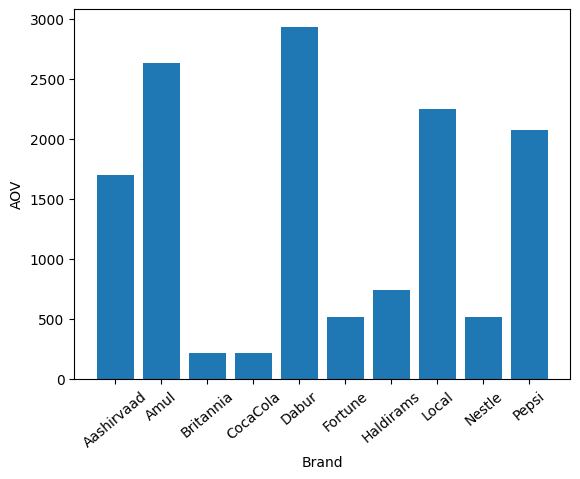

In [34]:
import matplotlib.pyplot as plt
brand_category_wise_aov = data.groupby(['Brand','Category'])['GrossAmount'].mean().reset_index(name='AOV')
brand_category_wise_aov = brand_category_wise_aov.sort_values(['Brand','AOV'],ascending=[True,True])

pd.set_option('display.float_format', '{:,.2f}'.format)

print(brand_category_wise_aov.to_string())
plt.bar(brand_category_wise_aov['Brand'],brand_category_wise_aov['AOV'])
plt.xticks(rotation=40)
plt.xlabel('Brand')
plt.ylabel('AOV')
plt.show()

Q4)How do invested value, operating charges, discounts, and profit vary across different Brands and Categories for Zepto?

In [35]:
import pandas as pd
invested_value_per_brand = data.groupby('Brand')['BuyingPrice'].sum()
total_invested_Value_per_category = data.groupby('Category')['BuyingPrice'].sum()
operating_charge_per_brand = data.groupby('Brand')['OperationCharges'].sum()
operating_charge_per_category = data.groupby('Category')['OperationCharges'].sum()
discount_per_brand = data.groupby('Brand')['DiscountAmount'].sum()
discount_per_category = data.groupby('Category')['DiscountAmount'].sum()
brand_level_profit_for_zepto = (
    data.groupby('Brand')['MRP'].sum()
    - invested_value_per_brand
    - discount_per_brand
    + data.groupby('Brand')['Order_Profit'].sum()
)

category_level_profit_for_zepto = (
    data.groupby('Category')['MRP'].sum()
    - total_invested_Value_per_category
    - discount_per_category
    + data.groupby('Category')['Order_Profit'].sum()
)

brand_table = pd.concat([
    invested_value_per_brand,
    operating_charge_per_brand,
    discount_per_brand,
    brand_level_profit_for_zepto
], axis=1)

brand_table.columns = [
    'Invested Value',
    'Operating Charges',
    'Discount',
    'Profit'
]

print("brand_wise_economics\n", brand_table.to_string())

category_table = pd.concat([
    total_invested_Value_per_category,
    operating_charge_per_category,
    discount_per_category,
    category_level_profit_for_zepto
], axis=1)

category_table.columns = [
    'Invested Value',
    'Operating Charges',
    'Discount',
    'Profit'
]

print("category_wise_economics\n", category_table.to_string())

brand_wise_economics
             Invested Value  Operating Charges     Discount        Profit
Brand                                                                   
Aashirvaad    2,368,836.24         367,359.48   176,752.92    289,000.77
Amul          2,333,715.07         292,282.33 1,469,165.48 -1,074,749.67
Britannia     1,718,661.92         186,061.80 1,708,176.84 -1,442,629.41
CocaCola      2,498,479.81         320,475.60 1,489,855.65 -1,056,224.52
Dabur         8,602,573.55       1,278,727.14 1,486,709.76    148,114.27
Fortune         587,487.97          84,267.27   140,057.43    -32,682.93
Haldirams     4,376,326.76         609,825.79 1,559,291.18   -748,349.18
Local         2,484,956.68         320,691.63 1,407,444.64   -969,397.97
Nestle        3,464,613.88         471,243.89 1,537,036.31   -911,443.73
Pepsi         2,010,674.08         239,215.91 1,560,989.34 -1,234,164.01
category_wise_economics
                             Invested Value  Operating Charges     Discount   

Q5)Which Brands and Categories have the highest and lowest number of promotions across different Promotion Types on the platform?

In [36]:
data = final_join.copy()
brand = data.groupby(['Brand','PromotionType'])['PromotionID'].count()
print("Brand_Promotion_Type_on_Platform\n",brand.to_string())
category = data.groupby(['Category','PromotionType'])['PromotionID'].count()
print("Category_Promotion_Type_on_Platform\n",category.to_string())

Brand_Promotion_Type_on_Platform
 Brand       PromotionType
Aashirvaad  BOGO               916
            Flat              1254
            Free Delivery     1272
            Percentage         976
Amul        BOGO              7562
            Flat             10439
            Free Delivery    10462
            Percentage        8221
Britannia   BOGO              8885
            Flat             12032
            Free Delivery    12257
            Percentage        9507
CocaCola    BOGO              7728
            Flat             10645
            Free Delivery    10565
            Percentage        8402
Dabur       BOGO              7792
            Flat             10516
            Free Delivery    10444
            Percentage        8411
Fortune     BOGO               756
            Flat               985
            Free Delivery      981
            Percentage         805
Haldirams   BOGO              8190
            Flat             11073
            Free Delivery    1

Q6)Analyze the monthly and yearly trends in Gross Amount, Profit, Revenue, and Buying Price. Calculate their month-on-month growth rates and visualize the year-wise Gross Amount and monthly growth trends.”

                             BuyingPrice  GrossAmount    NetAmount  Order_Profit  DiscountAmount
OrderDateTime OrderDateTime                                                                     
2023          1             1,114,231.48 3,527,345.08 2,911,731.98    141,770.54      462,364.05
              2             1,009,307.80 3,159,695.46 2,613,498.35    127,215.47      408,644.56
              3             1,125,901.58 3,526,062.62 2,915,862.04    142,014.26      456,734.16
              4             1,101,842.96 3,477,987.22 2,882,913.49    140,369.95      443,341.44
              5             1,113,370.25 3,532,198.18 2,914,772.60    141,941.09      464,016.50
              6             1,046,133.63 3,279,333.15 2,700,179.35    131,494.33      437,039.10
              7             1,099,023.48 3,427,415.98 2,824,275.72    137,491.83      454,494.17
              8             1,081,814.41 3,412,249.56 2,809,137.54    136,750.02      455,262.68
              9             1,

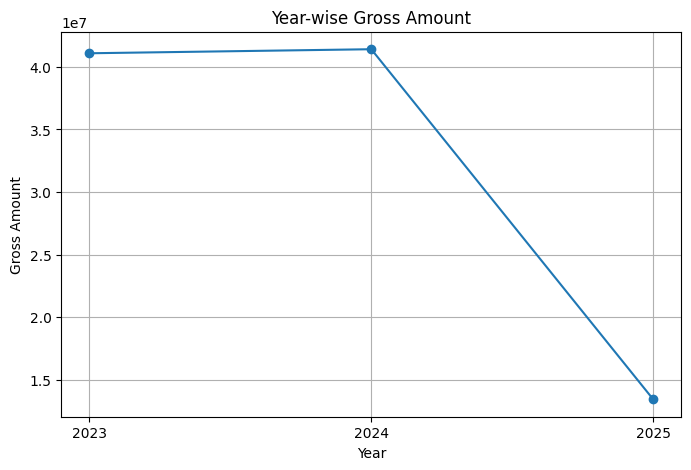

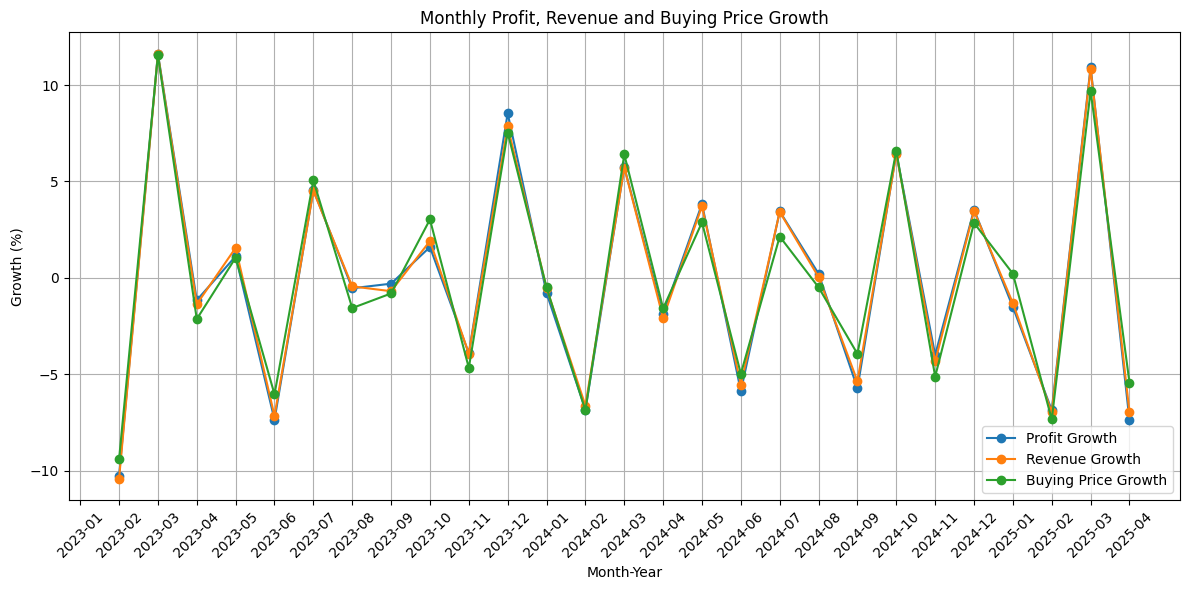

In [37]:
import pandas as pd

import matplotlib.pyplot as plt

data = sales_products.copy()

data['OrderDateTime'] = pd.to_datetime(data['OrderDateTime'])

month_year = data.groupby(

    [
        data['OrderDateTime'].dt.year,
        data['OrderDateTime'].dt.month
    ]

)[['BuyingPrice', 'GrossAmount', 'NetAmount', 'Order_Profit','DiscountAmount']].sum()

print(month_year.to_string())

growth_table = month_year.copy()

growth_table['Profit_Growth'] = growth_table['Order_Profit'].pct_change() * 100

growth_table['Revenue_Growth'] = growth_table['GrossAmount'].pct_change() * 100

growth_table['Buying_Price_Growth'] = growth_table['BuyingPrice'].pct_change() * 100

growth_table['NetAmount_Growth'] = growth_table['NetAmount'].pct_change() * 100

growth_table['GrossAmount_Growth'] = growth_table['GrossAmount'].pct_change() * 100

growth_table['DiscountAmount_Growth'] = growth_table['DiscountAmount'].pct_change()*100

print("\nGrowth Table:")

print(growth_table[
    [
        'Profit_Growth',
        'Revenue_Growth',
        'Buying_Price_Growth',
        'NetAmount_Growth',
        'GrossAmount_Growth',
        'DiscountAmount_Growth'
    ]
].to_string())

pmonth_year = data.groupby(

    data['OrderDateTime'].dt.year

)['GrossAmount'].sum()

pmonth_year.index = pmonth_year.index.astype(int)

print("\nYear-wise Gross Amount:")

print(pmonth_year)

plt.figure(figsize=(8, 5))

plt.plot(

    pmonth_year.index,

    pmonth_year.values,

    marker='o'

)

plt.xticks(

    pmonth_year.index,

    pmonth_year.index.astype(str)

)

plt.xlabel('Year')

plt.ylabel('Gross Amount')

plt.title('Year-wise Gross Amount')

plt.grid(True)

plt.show()

month_labels = [

    f"{year}-{month:02d}"

    for year, month in month_year.index

]

plt.figure(figsize=(12, 6))

plt.plot(

    month_labels,

    growth_table['Profit_Growth'],

    marker='o',

    label='Profit Growth'

)

plt.plot(

    month_labels,

    growth_table['Revenue_Growth'],

    marker='o',

    label='Revenue Growth'

)

plt.plot(

    month_labels,

    growth_table['Buying_Price_Growth'],

    marker='o',

    label='Buying Price Growth'

)

plt.xlabel('Month-Year')

plt.ylabel('Growth (%)')

plt.title('Monthly Profit, Revenue and Buying Price Growth')

plt.xticks(rotation=45)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

Q7)Calculate the average operational charges per employee for each store and identify the stores with the highest and lowest average operational charges per employee.

In [38]:
data = final_join.copy()

x = data[['StoreID','OpeningYear','Employee_Count','OperationCharges']].copy()

x['average_operating_charges_per_employee'] = (
    x['OperationCharges'] / x['Employee_Count']
)

x.style.format({
    'OpeningYear': '{:.0f}',
    'Employee_Count': '{:.0f}',
    'OperationCharges': '{:.2f}',
    'average_operating_charges_per_employee': '{:.2f}'
})
print(x.head())
print("The maximum average operating charges per employee is:\n",x['average_operating_charges_per_employee'].max())
print("The minimum average operating charges per employee is:\n",x['average_operating_charges_per_employee'].min())

print("The maximum Count across each store is:\n",x['Employee_Count'].max())
print("The minimum count across each store is:\n",x['Employee_Count'].min())

         StoreID  OpeningYear  Employee_Count  OperationCharges  \
0  STR6TQ4D5J9IH         2022              19             88.15   
1  STR4SN7WAP9LT         2022              15              6.21   
2  STRPOQGP6SIYN         2024              17             30.43   
3  STRCEBHPT31ZW         2023              28             12.80   
4  STRAD5LFMZJNX         2022              22              8.99   

   average_operating_charges_per_employee  
0                                    4.64  
1                                    0.41  
2                                    1.79  
3                                    0.46  
4                                    0.41  
The maximum average operating charges per employee is:
 24.116366666666675
The minimum average operating charges per employee is:
 -0.15373333333333333
The maximum Count across each store is:
 30
The minimum count across each store is:
 15


Q8)Calculate the average operational charges across each product category and identify the categories with the highest and lowest average operational charges.

In [39]:
pd.reset_option('display.float_format')

data = final_join.copy()

x = data.groupby('Category')['OperationCharges'].mean()

print(x.to_string(float_format=lambda v: f'{v:.2f}'))

Category
Beverages                    10.58
Biscuits                      2.45
Chocolates / Confectionery    0.31
Coffee / Beverages           23.84
Confectionery                 0.13
Dairy                         7.61
Grocery                      39.11
Health & Wellness            56.93
Instant Food                 11.23
Instant Food / Noodles       11.50
Snacks                        7.33
Sweets                       34.87


**III) Hypothesis Testing Analysis**

This section covers statistical hypothesis testing to determine whether delivery time has a significant impact on different order outcomes. Examples:

- Delivered vs. Cancelled Orders
- Delivered vs. Returned Orders
- Comparison of average delivery times
- Testing whether differences in delivery time are statistically significant
- Drawing conclusions using p-values and significance level

Q1)Check whether delivery times have a significant impact on whether an order is cancelled or returned?

1)Delivered vs. Cancelled Orders

H₀: There is no significant difference in the average delivery time between delivered and cancelled orders.

H₁: There is a significant difference in the average delivery time between delivered and cancelled orders.

2)Delivered vs. Returned Orders

H₀: There is no significant difference in the average delivery time between delivered and returned orders.

H₁: There is a significant difference in the average delivery time between delivered and returned orders.

In [40]:
import pandas as pd
from scipy.stats import ttest_ind

# 1. Isolate delivery minutes for each individual order status
deliver = data[data['OrderStatus'] == 'Delivered']['DeliveryMinutes']
cancel = data[data['OrderStatus'] == 'Cancelled']['DeliveryMinutes']
returned = data[data['OrderStatus'] == 'Returned']['DeliveryMinutes']

alpha = 0.05
print("=== Hypothesis Test 1: Delivered vs. Cancelled ===")
t_test_cancel, p_value_cancel = ttest_ind(deliver, cancel, nan_policy='omit')

print(f"T-statistic: {t_test_cancel:.4f}")
print(f"P-value:     {p_value_cancel:.4f}")

if p_value_cancel < alpha:
    print("Result:     Reject the null hypothesis.")
    print("Conclusion: The delivery minutes significantly affect whether an order is cancelled.")
else:
    print("Result:     Fail to reject the null hypothesis.")
    print("Conclusion: The delivery minutes do not significantly affect whether an order is cancelled.")



print("=== Hypothesis Test 2: Delivered vs. Returned ===")
t_test_return, p_value_return = ttest_ind(deliver, returned, nan_policy='omit')

print(f"T-statistic: {t_test_return:.4f}")
print(f"P-value:     {p_value_return:.4f}")

if p_value_return < alpha:
    print("Result:     Reject the null hypothesis.")
    print("Conclusion: The delivery minutes significantly affect whether an order is returned.")
else:
    print("Result:     Fail to reject the null hypothesis.")
    print("Conclusion: The delivery minutes do not significantly affect whether an order is returned.")

=== Hypothesis Test 1: Delivered vs. Cancelled ===
T-statistic: 0.5217
P-value:     0.6019
Result:     Fail to reject the null hypothesis.
Conclusion: The delivery minutes do not significantly affect whether an order is cancelled.
=== Hypothesis Test 2: Delivered vs. Returned ===
T-statistic: 0.5160
P-value:     0.6058
Result:     Fail to reject the null hypothesis.
Conclusion: The delivery minutes do not significantly affect whether an order is returned.


Q2)Does the quantity of products per order significantly affect the delivery time taken?

H0 = "the quantity of the products per order do not affect the delivery time taken"

H1 = "the quantity of the products per order do affect the delivery time take"

In [41]:
from scipy.stats import pearsonr
alpha = 0.05
correlation,p_value = pearsonr(data['DeliveryMinutes'],data['Quantity'])
print(correlation,end='\n')
if correlation >= 0.7:
    print("There is a strong positive correlation.")
elif correlation >= 0.3:
    print("There is a moderate positive correlation.")
elif correlation > 0:
    print("There is a weak positive correlation.")
elif correlation == 0:
    print("There is no correlation.")
elif correlation > -0.3:
    print("There is a weak negative correlation.")
elif correlation >= -0.7:
    print("There is a moderate negative correlation.")
else:
    print("There is a strong negative correlation.")
if(p_value<alpha):
  print("the null statment is rejected")
  print("the quantity of the products per order do affect the delivery time take")

else:
  print("failed to reject the null statement")
  print("the quantity of the products per order do not affect the delivery time taken")

-0.001609833302192256
There is a weak negative correlation.
failed to reject the null statement
the quantity of the products per order do not affect the delivery time taken


Q3) Is there a statistically significant linear correlation between the quantity of products per order and the delivery time taken?

H0 = "There is no linear correlation between Quantity and DeliveryMinutes in the population."

H1 = "There is a statistically significant linear correlation between Quantity and DeliveryMinutes in the population."

In [42]:
from scipy.stats import pearsonr
alpha = 0.05
correlation,p_value = pearsonr(data['DeliveryMinutes'],data['Quantity'])
h0 = "There is no linear correlation between Quantity and DeliveryMinutes in the population"
h1 = "There is a statistically significant linear correlation between Quantity and DeliveryMinutes in the population."
print(correlation,end='\n')
if correlation >= 0.7:
    print("There is a strong positive correlation.")
elif correlation >= 0.3:
    print("There is a moderate positive correlation.")
elif correlation > 0:
    print("There is a weak positive correlation.")
elif correlation == 0:
    print("There is no correlation.")
elif correlation > -0.3:
    print("There is a weak negative correlation.")
elif correlation >= -0.7:
    print("There is a moderate negative correlation.")
else:
    print("There is a strong negative correlation.")

if(p_value<alpha):
  print("the null statment is rejected")
  print(h1)

else:
  print("failed to reject the null statement")
  print(h0)

-0.001609833302192256
There is a weak negative correlation.
failed to reject the null statement
There is no linear correlation between Quantity and DeliveryMinutes in the population


Q4)Is there a correlation between the city in which an order is placed and the Gross Amount of that order?

H0 (Null Hypothesis): There is no linear correlation between belonging to a particular city and the Gross Amount.

H1 (Alternative Hypothesis): There is a statistically significant linear correlation between belonging to a particular city and the Gross Amount.

In [43]:
from scipy.stats import pearsonr
import pandas as pd

alpha = 0.05
data = final_join.copy()
h0 = "There is no linear correlation between belonging to a particular city and the Gross Amount."
h1 = "There is a statistically significant linear correlation between belonging to a particular city and the Gross Amount."

print("H0:", h0)
print("H1:", h1)

city_encoded = pd.get_dummies(data['City'], dtype=int)

for city in city_encoded.columns:
    correlation, p_value = pearsonr(
        city_encoded[city],
        data['GrossAmount']
    )

    print(f"\nCity: {city}")
    print("Correlation:", correlation)

    if correlation >= 0.7:
        print("There is a strong positive correlation.")
    elif correlation >= 0.3:
        print("There is a moderate positive correlation.")
    elif correlation > 0:
        print("There is a weak positive correlation.")
    elif correlation == 0:
        print("There is no correlation.")
    elif correlation > -0.3:
        print("There is a weak negative correlation.")
    elif correlation >= -0.7:
        print("There is a moderate negative correlation.")
    else:
        print("There is a strong negative correlation.")

    if p_value < alpha:
        print("The null hypothesis is rejected.")
        print(h1)
    else:
        print("Failed to reject the null hypothesis.")
        print(h0)

H0: There is no linear correlation between belonging to a particular city and the Gross Amount.
H1: There is a statistically significant linear correlation between belonging to a particular city and the Gross Amount.

City: Bangalore
Correlation: -1.1454295799910759e-05
There is a weak negative correlation.
Failed to reject the null hypothesis.
There is no linear correlation between belonging to a particular city and the Gross Amount.

City: Chennai
Correlation: -0.002821904523616107
There is a weak negative correlation.
Failed to reject the null hypothesis.
There is no linear correlation between belonging to a particular city and the Gross Amount.

City: Delhi
Correlation: -0.0003732532311577798
There is a weak negative correlation.
Failed to reject the null hypothesis.
There is no linear correlation between belonging to a particular city and the Gross Amount.

City: Gurgaon
Correlation: -0.0008726170635552386
There is a weak negative correlation.
Failed to reject the null hypothesis.

Q5)Is there a significant linear correlation between the Quantity of products ordered and the GrossAmount of transactions? If a correlation exists, determine its strength and direction using Pearson's correlation coefficient at a 5% significance level."
H₀: There is no significant linear correlation between Quantity and GrossAmount in the population.

H₁: There is a significant linear correlation between Quantity and GrossAmount in the population.

In [44]:
from scipy.stats import pearsonr
alpha = 0.05
H0 =  "There is no significant linear correlation between Quantity and GrossAmount in the population."
H1 = "There is a significant linear correlation between Quantity and GrossAmount in the population."
correlation,p_value = pearsonr(data['Quantity'],data['GrossAmount'])
if correlation >= 0.7:
    print("There is a strong positive correlation.")
elif correlation >= 0.3:
    print("There is a moderate positive correlation.")
elif correlation > 0:
    print("There is a weak positive correlation.")
elif correlation == 0:
    print("There is no correlation.")
elif correlation > -0.3:
    print("There is a weak negative correlation.")
elif correlation >= -0.7:
    print("There is a moderate negative correlation.")
else:
    print("There is a strong negative correlation.")
print(correlation)
if(p_value<alpha):
  print("the null statment is rejected")
  print(h1)

else:
  print("failed to reject the null statement")
  print(h0)

There is a weak positive correlation.
0.2925444088096647
the null statment is rejected
There is a statistically significant linear correlation between belonging to a particular city and the Gross Amount.


Q6)Is there a significant linear correlation between DiscountAmount and NetAmount? If a correlation exists, determine its strength and direction using Pearson's correlation coefficient at a 5% significance level."
Hypothesis
- Null Hypothesis (H₀): There is no significant linear correlation between DiscountAmount and NetAmount in the population. (\(\rho = 0\))
- Alternative Hypothesis (H₁): There is a significant linear correlation between DiscountAmount and NetAmount in the population. (\(\rho \neq 0\))

In [45]:

from scipy.stats import pearsonr

alpha = 0.05

H0 = "There is no significant linear correlation between DiscountAmount and NetAmount in the population."
H1 = "There is a significant linear correlation between DiscountAmount and NetAmount in the population."

correlation, p_value = pearsonr(data['DiscountAmount'], data['NetAmount'])

if correlation >= 0.7:
    print("There is a strong positive correlation.")
elif correlation >= 0.3:
    print("There is a moderate positive correlation.")
elif correlation > 0:
    print("There is a weak positive correlation.")
elif correlation == 0:
    print("There is no correlation.")
elif correlation > -0.3:
    print("There is a weak negative correlation.")
elif correlation >= -0.7:
    print("There is a moderate negative correlation.")
else:
    print("There is a strong negative correlation.")

print("Pearson correlation coefficient:", correlation)

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(H1)
else:
    print("Fail to reject the null hypothesis.")
    print(H0)


There is a weak negative correlation.
Pearson correlation coefficient: -0.021830719801313524
Reject the null hypothesis.
There is a significant linear correlation between DiscountAmount and NetAmount in the population.


Q7)Is there a significant linear correlation between DeliveryMinutes and NetAmount? If a correlation exists, determine its strength and direction using Pearson's correlation coefficient at a 5% significance level."
Hypothesis
- Null Hypothesis (H₀): There is no significant linear correlation between DeliveryMinutes and NetAmount in the population.
- Alternative Hypothesis (H₁): There is a significant linear correlation between DeliveryMinutes and NetAmount in the population.

In [46]:

from scipy.stats import pearsonr

alpha = 0.05

H0 = "There is no significant linear correlation between DeliveryMinutes and NetAmount in the population."
H1 = "There is a significant linear correlation between DeliveryMinutes and NetAmount in the population."

correlation, p_value = pearsonr(data['DeliveryMinutes'], data['NetAmount'])

if correlation >= 0.7:
    print("There is a strong positive correlation.")
elif correlation >= 0.3:
    print("There is a moderate positive correlation.")
elif correlation > 0:
    print("There is a weak positive correlation.")
elif correlation == 0:
    print("There is no correlation.")
elif correlation > -0.3:
    print("There is a weak negative correlation.")
elif correlation >= -0.7:
    print("There is a moderate negative correlation.")
else:
    print("There is a strong negative correlation.")

print("Pearson correlation coefficient:", correlation)

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(H1)
else:
    print("Fail to reject the null hypothesis.")
    print(H0)


There is a weak positive correlation.
Pearson correlation coefficient: 0.0011552370286825899
Fail to reject the null hypothesis.
There is no significant linear correlation between DeliveryMinutes and NetAmount in the population.


Q8)Is there a significant linear correlation between BuyingPrice and Order_Profit? If a correlation exists, determine its strength and direction using Pearson's correlation coefficient at a 5% significance level."
Hypothesis
- Null Hypothesis (H₀): There is no significant linear correlation between BuyingPrice and Order_Profit in the population.

- Alternative Hypothesis (H₁): There is a significant linear correlation between BuyingPrice and Order_Profit in the population

In [47]:
from scipy.stats import pearsonr
alpha = 0.05
H0 =  "There is no significant linear correlation between Quantity and GrossAmount in the population."
H1 = "There is a significant linear correlation between Quantity and GrossAmount in the population."
correlation,p_value = pearsonr(data['BuyingPrice'],data['Order_Profit'])
if correlation >= 0.7:
    print("There is a strong positive correlation.")
elif correlation >= 0.3:
    print("There is a moderate positive correlation.")
elif correlation > 0:
    print("There is a weak positive correlation.")
elif correlation == 0:
    print("There is no correlation.")
elif correlation > -0.3:
    print("There is a weak negative correlation.")
elif correlation >= -0.7:
    print("There is a moderate negative correlation.")
else:
    print("There is a strong negative correlation.")
print(correlation)
if(p_value<alpha):
  print("the null statment is rejected")
  print(h1)

else:
  print("failed to reject the null statement")
  print(h0)

There is a strong positive correlation.
0.8627921165029568
the null statment is rejected
There is a statistically significant linear correlation between belonging to a particular city and the Gross Amount.


Q9)Does order amount significantly differ across different customer segments and promotion types, and is there a significant interaction effect between customer segment and promotion type on order amount?

HYPOTEHSIS:

1.CustomerSegment
* Ho:There is not a significant difference in orderamount among different CustomerSegments
* H1:There is a signnificant difference in orderamount among different CustomerSegment

2.PromotionType


* Ho:There is not a siginificant difference in the promotion type across different CustomerSegments

* H1:There is a significant difference in the promotion type across different CustomerSegments

3.Interaction Effect

* Ho:There is not a siginifcant interaction effect between the customerSegment and PromotionType on orderamount

* H1:There is a significant interaction effect between the customerSegment and PromotionType on Orderamount






In [48]:
import pandas as pd
from statsmodels.formula.api import ols
import statsmodels.api as sm
data = final_join.copy()

sub_chart = data[['GrossAmount','CustomerSegment','PromotionType']]
test = ols('GrossAmount ~ C(CustomerSegment) *C(PromotionType)',data=sub_chart).fit()
annova_table = sm.stats.anova_lm(test,typ=2)
print(annova_table)

                                           sum_sq        df         F  \
C(CustomerSegment)                   8.072113e+04       2.0  0.168627   
C(PromotionType)                     2.213215e+05       3.0  0.308229   
C(CustomerSegment):C(PromotionType)  2.812047e+06       6.0  1.958131   
Residual                             7.502765e+10  313467.0       NaN   

                                       PR(>F)  
C(CustomerSegment)                   0.844824  
C(PromotionType)                     0.819467  
C(CustomerSegment):C(PromotionType)  0.067817  
Residual                                  NaN  


Q10)Does the category of a product have a significant association with the particular brand?

Hypothesis:

*  H0:There is no significant association between category and a particular brand.
* H1:There is a significant association between Category and Particular Brand



In [49]:
import pandas as pd
from scipy.stats import chi2_contingency
data = final_join.copy()
alpha = 0.05
contigency_table = pd.crosstab(data['Category'],data['Brand'])
chi2, p_value, dof,expected = chi2_contingency(contigency_table)
print("Chi-square statstic:",chi2)
print("P-value:",p_value)
if(p_value<alpha):
  print("Reject the null hypthesis:")
  print("There is a significant association between Category and Particular Brand")
else:
  print("Fail to reject the null hypothesis:")
  print("There is no significant association between category and a particular brand.")

Chi-square statstic: 1317983.2786573968
P-value: 0.0
Reject the null hypthesis:
There is a significant association between Category and Particular Brand


**IV).PREDICTION & FORECASTING ANALYSIS**

Q1)Predict the Gross Amount, Discount Amount, and Net Amount for each city based on the number of stores, and compare the predicted amounts with the actual amounts and their percentage differences.


In [50]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

model = LinearRegression()
data = final_join.copy()

city_count = data.groupby('City')['StoreID'].count().reset_index()
city_gross_amount = data.groupby('City')['GrossAmount'].sum().reset_index()
city_discount_amount = data.groupby('City')['DiscountAmount'].sum().reset_index()
city_net_amount = data.groupby('City')['NetAmount'].sum().reset_index()

x = city_count[['StoreID']]
y = city_gross_amount['GrossAmount']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)
model.fit(x_train, y_train)
predicted_gross = model.predict(x)
gross_r2 = r2_score(y_test, model.predict(x_test))

result = x.copy()
result['City'] = city_count['City'].values
result['Actual GrossAmount'] = y.values
result['Predicted GrossAmount'] = predicted_gross

a = city_count[['StoreID']]
b = city_discount_amount['DiscountAmount']

a_train, a_test, b_train, b_test = train_test_split(
    a, b, test_size=0.3, random_state=41
)
model.fit(a_train, b_train)
predicted_discount = model.predict(a)
discount_r2 = r2_score(b_test, model.predict(a_test))

result['Actual DiscountAmount'] = b.values
result['Predicted DiscountAmount'] = predicted_discount

c = city_count[['StoreID']]
d = city_net_amount['NetAmount']

c_train, c_test, d_train, d_test = train_test_split(
    c, d, test_size=0.3, random_state=42
)
model.fit(c_train, d_train)
predicted_net = model.predict(c)
net_r2 = r2_score(d_test, model.predict(c_test))

result['Actual NetAmount'] = d.values
result['Predicted NetAmount'] = predicted_net

amount_table = result[
    [
        'City',
        'Actual GrossAmount',
        'Predicted GrossAmount',
        'Actual DiscountAmount',
        'Predicted DiscountAmount',
        'Actual NetAmount',
        'Predicted NetAmount'
    ]
]

percent_table = result[['City']].copy()

percent_table['Gross_Predicted_Amount %'] = (
    (result['Predicted GrossAmount'] - result['Actual GrossAmount'])
    / result['Actual GrossAmount']
) * 100

percent_table['Discount_Predicted_Amount %'] = (
    (result['Predicted DiscountAmount'] - result['Actual DiscountAmount'])
    / result['Actual DiscountAmount']
) * 100

percent_table['Net_Predicted_Amount %'] = (
    (result['Predicted NetAmount'] - result['Actual NetAmount'])
    / result['Actual NetAmount']
) * 100

# R-squared values before the tables
print("R-SQUARED (R²) VALUES")
print(f"Gross Amount R²: {gross_r2:.4f}")
print(f"Discount Amount R²: {discount_r2:.4f}")
print(f"Net Amount R²: {net_r2:.4f}")

print("\nCURRENT AND PREDICTED AMOUNT")
print(amount_table.to_string(index=False))

print("\nPERCENTAGE DIFFERENCE")
print(percent_table.to_string(index=False))




R-SQUARED (R²) VALUES
Gross Amount R²: 0.4832
Discount Amount R²: 0.9941
Net Amount R²: 0.3807

CURRENT AND PREDICTED AMOUNT
     City  Actual GrossAmount  Predicted GrossAmount  Actual DiscountAmount  Predicted DiscountAmount  Actual NetAmount  Predicted NetAmount
Bangalore         10533772.56           1.050886e+07             1374951.72              1.377625e+06      8700879.7980         8.674480e+06
  Chennai         10638831.45           1.078713e+07             1404099.77              1.406866e+06      8772995.0960         8.910177e+06
    Delhi         10819490.39           1.085882e+07             1416191.56              1.414399e+06      8933133.8885         8.970896e+06
  Gurgaon         10416409.35           1.042093e+07             1370543.00              1.368385e+06      8593573.0325         8.600002e+06
Hyderabad         10847457.51           1.073946e+07             1403236.94              1.401857e+06      8972009.5415         8.869798e+06
  Kolkata         10961310.58

Q2)Predict the Revenue, Discount, and Profit for each store in every city based on the number of transactions, and compare the predicted values with the current values and their percentage changes.


In [51]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = final_join.copy()
model = LinearRegression()

# ================= OVERALL R² SCORES =================

overall_store = data.groupby('City')['StoreID'].count().reset_index()
overall_gross = data.groupby('City')['GrossAmount'].sum().reset_index()
overall_discount = data.groupby('City')['DiscountAmount'].sum().reset_index()
overall_profit = data.groupby('City')['NetAmount'].sum().reset_index()

x = overall_store[['StoreID']]

# Overall Revenue R²
y = overall_gross['GrossAmount']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)
model.fit(x_train, y_train)
overall_revenue_r2 = r2_score(y_test, model.predict(x_test))

# Overall Discount R²
y = overall_discount['DiscountAmount']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=41
)
model.fit(x_train, y_train)
overall_discount_r2 = r2_score(y_test, model.predict(x_test))

# Overall Profit R²
y = overall_profit['NetAmount']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)
model.fit(x_train, y_train)
overall_profit_r2 = r2_score(y_test, model.predict(x_test))

print("=" * 60)
print("OVERALL R-SQUARED (R²) SCORES")
print("=" * 60)
print(f"Overall Revenue R²:  {overall_revenue_r2:.4f}")
print(f"Overall Discount R²: {overall_discount_r2:.4f}")
print(f"Overall Profit R²:   {overall_profit_r2:.4f}")


# ================= CITY-WISE TABLES AND R² SCORES =================

all_city = data['City'].unique()

for a in all_city:
    city = data[data['City'] == a]

    store = city.groupby('StoreName')['StoreID'].count().reset_index()
    gross = city.groupby('StoreName')['GrossAmount'].sum().reset_index()
    discount = city.groupby('StoreName')['DiscountAmount'].sum().reset_index()
    profit = city.groupby('StoreName')['NetAmount'].sum().reset_index()

    x = store[['StoreID']]

    # Revenue
    y = gross['GrossAmount']
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )
    model.fit(x_train, y_train)
    price = model.predict(x)
    revenue_r2 = r2_score(y_test, model.predict(x_test))

    revenue_table = store[['StoreName']].copy()
    revenue_table['City'] = a
    revenue_table['Current-Revenue'] = y.values
    revenue_table['Predicted-Revenue'] = price
    revenue_table['Revenue-Pct-Change'] = (
        (price - y.values) / y.values
    ) * 100

    print(f"\n{'=' * 60}")
    print(f"CITY: {a} — REVENUE")
    print(f"Revenue R²: {revenue_r2:.4f}")
    print(revenue_table.to_string(index=False))

    # Discount
    y = discount['DiscountAmount']
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )
    model.fit(x_train, y_train)
    price = model.predict(x)
    discount_r2 = r2_score(y_test, model.predict(x_test))

    discount_table = store[['StoreName']].copy()
    discount_table['City'] = a
    discount_table['Current-Discount'] = y.values
    discount_table['Predicted-Discount'] = price
    discount_table['Discount-Pct-Change'] = (
        (price - y.values) / y.values
    ) * 100

    print(f"\nCITY: {a} — DISCOUNT")
    print(f"Discount R²: {discount_r2:.4f}")
    print(discount_table.to_string(index=False))

    # Profit
    y = profit['NetAmount']
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )
    model.fit(x_train, y_train)
    price = model.predict(x)
    profit_r2 = r2_score(y_test, model.predict(x_test))

    profit_table = store[['StoreName']].copy()
    profit_table['City'] = a
    profit_table['Current-Profit'] = y.values
    profit_table['Predicted-Profit'] = price
    profit_table['Profit-Pct-Change'] = (
        (price - y.values) / y.values
    ) * 100

    print(f"\nCITY: {a} — PROFIT")
    print(f"Profit R²: {profit_r2:.4f}")
    print(profit_table.to_string(index=False))

OVERALL R-SQUARED (R²) SCORES
Overall Revenue R²:  0.4832
Overall Discount R²: 0.9941
Overall Profit R²:   0.3807

CITY: Pune — REVENUE
Revenue R²: 0.0933
           StoreName City  Current-Revenue  Predicted-Revenue  Revenue-Pct-Change
  Zepto Dark Store 1 Pune         71075.96       59477.935853          -16.317788
 Zepto Dark Store 10 Pune         59163.86       60872.938246            2.888720
Zepto Dark Store 100 Pune         64347.64       57086.503178          -11.284232
Zepto Dark Store 101 Pune         65856.08       58481.505572          -11.198016
Zepto Dark Store 102 Pune         57012.69       57285.789234            0.479015
Zepto Dark Store 103 Pune         50031.50       61470.796415           22.864188
Zepto Dark Store 104 Pune         60093.80       56090.072897           -6.662463
Zepto Dark Store 105 Pune         67259.44       58680.791628          -12.754564
Zepto Dark Store 106 Pune         46277.96       57285.789234           23.786332
Zepto Dark Store 107 Pune

Q3)Predict the Operation Charges and Buying Price for each store in every city based on the number of transactions, and compare the predicted values with the current values and their percentage changes.


In [52]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = final_join.copy()
model = LinearRegression()

# ================= OVERALL R² SCORES =================

overall_store = data.groupby('City')['StoreID'].count().reset_index()
overall_operation = data.groupby('City')['OperationCharges'].sum().reset_index()
overall_buying = data.groupby('City')['BuyingPrice'].sum().reset_index()

x = overall_store[['StoreID']]

# Overall Operation Charges R²
y = overall_operation['OperationCharges']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)
model.fit(x_train, y_train)
operation_r2 = r2_score(y_test, model.predict(x_test))

# Overall Buying Price R²
y = overall_buying['BuyingPrice']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)
model.fit(x_train, y_train)
buying_r2 = r2_score(y_test, model.predict(x_test))

print("=" * 60)
print("OVERALL R-SQUARED (R²) SCORES")
print("=" * 60)
print(f"Overall Operation Charges R²: {operation_r2:.4f}")
print(f"Overall Buying Price R²:      {buying_r2:.4f}")


# ================= CITY-WISE R² SCORES AND TABLES =================

all_city = data['City']

for a in all_city.unique():
    city = data[data['City'] == a]

    store = city.groupby('StoreName')['StoreID'].count().reset_index()
    operation = city.groupby('StoreName')['OperationCharges'].sum().reset_index()
    buying = city.groupby('StoreName')['BuyingPrice'].sum().reset_index()

    x = store[['StoreID']]

    # Operation Charges
    y = operation['OperationCharges']
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )
    model.fit(x_train, y_train)
    price = model.predict(x)
    operation_city_r2 = r2_score(y_test, model.predict(x_test))

    operation_table = store[['StoreName']].copy()
    operation_table['City'] = a
    operation_table['Current-OperationCharges'] = y.values
    operation_table['Predicted-OperationCharges'] = price
    operation_table['OperationCharges-Pct-Change'] = (
        (price - y.values) / y.values
    ) * 100

    print(f"\n{'=' * 60}")
    print(f"CITY: {a} — OPERATION CHARGES")
    print(f"Operation Charges R²: {operation_city_r2:.4f}")
    print(operation_table.to_string())

    # Buying Price
    y = buying['BuyingPrice']
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, random_state=42
    )
    model.fit(x_train, y_train)
    price = model.predict(x)
    buying_city_r2 = r2_score(y_test, model.predict(x_test))

    buying_table = store[['StoreName']].copy()
    buying_table['City'] = a
    buying_table['Current-BuyingPrice'] = y.values
    buying_table['Predicted-BuyingPrice'] = price
    buying_table['BuyingPrice-Pct-Change'] = (
        (price - y.values) / y.values
    ) * 100

    print(f"\nCITY: {a} — BUYING PRICE")
    print(f"Buying Price R²: {buying_city_r2:.4f}")
    print(buying_table.to_string())

OVERALL R-SQUARED (R²) SCORES
Overall Operation Charges R²: 0.3807
Overall Buying Price R²:      0.5363

CITY: Pune — OPERATION CHARGES
Operation Charges R²: 0.0504
                StoreName  City  Current-OperationCharges  Predicted-OperationCharges  OperationCharges-Pct-Change
0      Zepto Dark Store 1  Pune                 3149.2445                 2581.399869                   -18.031138
1     Zepto Dark Store 10  Pune                 2555.1925                 2636.500476                     3.182069
2    Zepto Dark Store 100  Pune                 2857.9005                 2486.941685                   -12.980117
3    Zepto Dark Store 101  Pune                 2904.4505                 2542.042292                   -12.477686
4    Zepto Dark Store 102  Pune                 2473.5810                 2494.813201                     0.858359
5    Zepto Dark Store 103  Pune                 2101.0795                 2660.115022                    26.607062
6    Zepto Dark Store 104  Pun

Q4)Predict the Gross Amount, Discount Amount, and Net Amount for each brand based on the number of products, and compare the predicted values with the actual values and their percentage changes.


In [53]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = final_join.copy()
model = LinearRegression()

brand_value = data.groupby('Brand')['ProductName'].count().reset_index()
gross = data.groupby('Brand')['GrossAmount'].sum().reset_index()
discount = data.groupby('Brand')['DiscountAmount'].sum().reset_index()
net = data.groupby('Brand')['NetAmount'].sum().reset_index()

x = brand_value[['ProductName']]

# Gross Amount
y = gross['GrossAmount']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)
model.fit(x_train, y_train)
predicted_revenue = model.predict(x)
gross_r2 = r2_score(y_test, model.predict(x_test))

# Discount Amount
y = discount['DiscountAmount']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)
model.fit(x_train, y_train)
predicted_discount = model.predict(x)
discount_r2 = r2_score(y_test, model.predict(x_test))

# Net Amount
y = net['NetAmount']
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42
)
model.fit(x_train, y_train)
predicted_net = model.predict(x)
net_r2 = r2_score(y_test, model.predict(x_test))

table = brand_value[['Brand']].copy()

table['GrossAmount_value'] = gross['GrossAmount'].values
table['Predicted-GrossAmount'] = predicted_revenue
table['GrossAmount-Pct-Change'] = (
    (predicted_revenue - gross['GrossAmount'].values)
    / gross['GrossAmount'].values
) * 100

table['DiscountAmount_value'] = discount['DiscountAmount'].values
table['Predicted-DiscountAmount'] = predicted_discount
table['DiscountAmount-Pct-Change'] = (
    (predicted_discount - discount['DiscountAmount'].values)
    / discount['DiscountAmount'].values
) * 100

table['NetAmount_value'] = net['NetAmount'].values
table['Predicted-NetAmount'] = predicted_net
table['NetAmount-Pct-Change'] = (
    (predicted_net - net['NetAmount'].values)
    / net['NetAmount'].values
) * 100

# R² scores before the table
print("=" * 60)
print("R-SQUARED (R²) SCORES")
print("=" * 60)
print(f"Gross Amount R²:    {gross_r2:.4f}")
print(f"Discount Amount R²: {discount_r2:.4f}")
print(f"Net Amount R²:      {net_r2:.4f}")

print("\nCURRENT AND PREDICTED AMOUNTS BY BRAND")
print(table.to_string(index=False))


R-SQUARED (R²) SCORES
Gross Amount R²:    -0.9593
Discount Amount R²: 0.9974
Net Amount R²:      -0.9438

CURRENT AND PREDICTED AMOUNTS BY BRAND
     Brand  GrossAmount_value  Predicted-GrossAmount  GrossAmount-Pct-Change  DiscountAmount_value  Predicted-DiscountAmount  DiscountAmount-Pct-Change  NetAmount_value  Predicted-NetAmount  NetAmount-Pct-Change
Aashirvaad         7523942.55           5.259521e+06              -30.096214             176752.92              1.759841e+05                  -0.434980     6.979830e+06         7.939659e+06             13.751467
      Amul         7314812.11           1.091524e+07               49.221029            1469165.48              1.466746e+06                  -0.164706     5.553364e+06         9.133882e+06             64.474749
 Britannia         5429412.78           1.196642e+07              120.399834            1708176.84              1.706648e+06                  -0.089485     3.535174e+06         9.355842e+06            164.650095
  CocaC

# Q5)Predict the Gross Amount, Discount Amount,Net Amount for each category along with its operational charges based on the number of products, and compare the predicted values with the actual values and their percentage changes.

In [54]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = final_join.copy()

model = LinearRegression()

category_value = data.groupby('Category')['ProductName'].count().reset_index()

gross = data.groupby('Category')['GrossAmount'].sum().reset_index()
discount = data.groupby('Category')['DiscountAmount'].sum().reset_index()
net = data.groupby('Category')['NetAmount'].sum().reset_index()
operation_charge = data.groupby('Category')['OperationCharges'].sum().reset_index()

x = category_value[['ProductName']]
y = gross['GrossAmount']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model.fit(x_train, y_train)

predicted_revenue = model.predict(x)
gross_r2 = r2_score(y_test, model.predict(x_test))

x = category_value[['ProductName']]
y = discount['DiscountAmount']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model.fit(x_train, y_train)

predicted_discount = model.predict(x)
discount_r2 = r2_score(y_test, model.predict(x_test))

x = category_value[['ProductName']]
y = operation_charge['OperationCharges']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model.fit(x_train, y_train)

operating_value = model.predict(x)
operation_r2 = r2_score(y_test, model.predict(x_test))

x = category_value[['ProductName']]
y = net['NetAmount']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model.fit(x_train, y_train)

predicted_net = model.predict(x)
net_r2 = r2_score(y_test, model.predict(x_test))

table = category_value.copy()

table['Revenue'] = gross['GrossAmount']
table['predicted_revenue'] = predicted_revenue
table['Revenue-Growth'] = (
    (predicted_revenue - gross['GrossAmount']) /
    gross['GrossAmount'] * 100
)

table['DiscountAmount'] = discount['DiscountAmount']
table['Predicted_DiscountAmount'] = predicted_discount
table['DiscountAmount-Growth'] = (
    (predicted_discount - discount['DiscountAmount']) /
    discount['DiscountAmount'] * 100
)

table['OperationCharges'] = operation_charge['OperationCharges']
table['Predicted_OperationCharges'] = operating_value
table['OperationCharges-Growth'] = (
    (operating_value - operation_charge['OperationCharges']) /
    operation_charge['OperationCharges'] * 100
)

table['NetRevenue'] = net['NetAmount']
table['Predicted_net_Revenue'] = predicted_net
table['NetRevenue-Growth'] = (
    (predicted_net - net['NetAmount']) /
    net['NetAmount'] * 100
)

table = table.drop(columns=['ProductName'])

print("R-SQUARED (R²) SCORES")
print(f"Revenue R²: {gross_r2:.4f}")
print(f"Discount Amount R²: {discount_r2:.4f}")
print(f"Operation Charges R²: {operation_r2:.4f}")
print(f"Net Revenue R²: {net_r2:.4f}")

print("\nCATEGORY-WISE PREDICTION TABLE")
print(table.to_string())

R-SQUARED (R²) SCORES
Revenue R²: 0.7727
Discount Amount R²: 1.0000
Operation Charges R²: 0.6836
Net Revenue R²: 0.6836

CATEGORY-WISE PREDICTION TABLE
                      Category      Revenue  predicted_revenue  Revenue-Growth  DiscountAmount  Predicted_DiscountAmount  DiscountAmount-Growth  OperationCharges  Predicted_OperationCharges  OperationCharges-Growth    NetRevenue  Predicted_net_Revenue  NetRevenue-Growth
0                    Beverages  21279649.37       1.616079e+07      -24.055204      3382042.98              3.383724e+06               0.049696       894880.3195               638853.123818               -28.610216  1.700273e+07           1.213821e+07         -28.610216
1                     Biscuits   2620480.04       8.409920e+06      220.930497      1178473.43              1.178344e+06              -0.011004        72100.3305               361578.793176               401.493947  1.369906e+06           6.869997e+06         401.493947
2   Chocolates / Confectionery    5

Q6)Predict the Gross Amount for each Payment Method using Linear Regression, and compare the predicted Gross Amount with the actual Gross Amount along with the percentage change.

In [55]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = final_join.copy()

# Convert PaymentMethod into separate binary columns
x = pd.get_dummies(
    data[['PaymentMethod']].astype(str),
    columns=['PaymentMethod'],
    dtype=int
)

y = data['GrossAmount']

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.1, random_state=40
)

model = LinearRegression()
model.fit(x_train, y_train)

# Predict GrossAmount for all rows
data['Predicted_GrossAmount'] = model.predict(x)

# Calculate R-squared on test data
r2 = r2_score(y_test, model.predict(x_test))

# Group actual and predicted amounts by payment method
table = data.groupby('PaymentMethod').agg(
    GrossAmount=('GrossAmount', 'sum'),
    Predicted_GrossAmount=('Predicted_GrossAmount', 'sum')
).reset_index()

# Calculate percentage difference
table['GrossAmount_pct'] = (
    (table['Predicted_GrossAmount'] - table['GrossAmount']) /
    table['GrossAmount'].replace(0, float('nan'))
) * 100

print("R-SQUARED (R²) SCORE")
print(f"Gross Amount R²: {r2:.4f}")

print("\nPAYMENT METHOD-WISE PREDICTION TABLE")
print(table.to_string(index=False))

R-SQUARED (R²) SCORE
Gross Amount R²: -0.0001

PAYMENT METHOD-WISE PREDICTION TABLE
PaymentMethod  GrossAmount  Predicted_GrossAmount  GrossAmount_pct
         Cash   4770283.42           4.786043e+06         0.330363
  Credit Card  11348427.99           1.131933e+07        -0.256434
   Debit Card   7579007.34           7.551626e+06        -0.361278
          UPI  62722469.43           6.273059e+07         0.012942
       Wallet   9518008.15           9.492216e+06        -0.270988


Q7)Predict the cumulative number of customers for the next six years using Linear Regression based on SignupDate, and evaluate the model using the R² score and estimated yearly customer growth trend.

In [56]:

import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

data = final_join.copy()

data['SignupDate'] = pd.to_datetime(
    data['SignupDate'], errors='coerce'
)

customer_data = data[['CustomerID', 'SignupDate']].dropna()

customer_data = (
    customer_data.groupby('CustomerID', as_index=False)['SignupDate']
    .min()
)

customer_data['Year'] = customer_data['SignupDate'].dt.year

yearly_customers = (
    customer_data.groupby('Year')['CustomerID']
    .nunique()
    .reset_index(name='NewCustomers')
    .sort_values('Year')
)

yearly_customers['CumulativeCustomers'] = (
    yearly_customers['NewCustomers'].cumsum()
)

print("\nYearly Customer Growth:")
print(yearly_customers.to_string(index=False))

yearly_customers['YearNumber'] = np.arange(
    1, len(yearly_customers) + 1
)

X = yearly_customers[['YearNumber']]
y = yearly_customers['CumulativeCustomers']

model = LinearRegression()
model.fit(X, y)

yearly_customers['PredictedCustomers'] = (
    model.predict(X).round().astype(int)
)

r2 = r2_score(
    yearly_customers['CumulativeCustomers'],
    model.predict(X)
)

print("\nLinear Regression Results:")
print(f"Model R² Score: {r2:.4f}")
print(
    f"Estimated Yearly Growth Trend: "
    f"{model.coef_[0]:.2f} customers per year"
)

future_years = 6

last_year_number = yearly_customers['YearNumber'].max()
last_year = int(yearly_customers['Year'].max())

future_data = pd.DataFrame({
    'YearNumber': range(
        last_year_number + 1,
        last_year_number + future_years + 1
    )
})

future_data['Year'] = range(
    last_year + 1,
    last_year + future_years + 1
)

future_data['PredictedCustomers'] = (
    model.predict(future_data[['YearNumber']])
    .clip(min=0)
    .round()
    .astype(int)
)

last_actual_customers = int(
    yearly_customers['CumulativeCustomers'].iloc[-1]
)

future_data['PredictedIncrease'] = (
    future_data['PredictedCustomers'] - last_actual_customers
).clip(lower=0)

print("\nPredicted Cumulative Customer Growth for the Next 6 Years:")
print(
    future_data[
        ['Year', 'PredictedCustomers', 'PredictedIncrease']
    ].to_string(index=False)
)


Yearly Customer Growth:
 Year  NewCustomers  CumulativeCustomers
 2021         11886                11886
 2022         11306                23192
 2023          1791                24983
 2024            17                25000

Linear Regression Results:
Model R² Score: 0.7082
Estimated Yearly Growth Trend: 4113.30 customers per year

Predicted Cumulative Customer Growth for the Next 6 Years:
 Year  PredictedCustomers  PredictedIncrease
 2025               31548               6548
 2026               35662              10662
 2027               39775              14775
 2028               43888              18888
 2029               48002              23002
 2030               52115              27115


END OF ALL EXPLORATARY DATA ANALYSIS




INSIGHTS:

**[A]Inital exploration insights**

1)After loading the files we identified missing (null) values in the Sales file across Quantity, Unit Price, Gross Amount, Net Amount, Discount Amount, Delivery Minutes, Order Status, Operational Charges, and Order Profit. These missing values needed to be addressed before joining the Sales file with the other datasets. We handled them using appropriate statistical methods and subsequently verified the results to ensure data consistency and completeness.

Additionally, using the `info()` function, we identified the total number of entries (rows) present in each dataset. The Payments file contained 5 entries, Products contained 2,200 entries, Sales contained 313,480 entries, Stores contained 180 entries, and Customers contained 25,000 entries. This helped us understand the size and structure of each dataset before proceeding with further analysis and joining the files.
Furthermore, date-related columns, such as Registration Date and Order Date, were converted into the appropriate datetime format. Wherever required, the year was also extracted to facilitate further analysis.

2)Based on the distribution of quantity analysis we can make a observation that maximum amount of orders have quantity amount of 2 while rest are in between the range 62,200 to 62800.The quantities number is maximum is 5 and lowest is 1 and hence majority of orders have deliverable items are less than 10 so on average each order will definitely have 1 to 2 delivering quantities.

3)The data reveals a high-volume, low-margin retail/e-commerce structure, where a typical customer transaction generates a net revenue of **106.63** and a relatively modest profit of **5.19**. However, the presence of more than **33,000 high-value outlier transactions** has a significant impact on the overall business performance. These transactions increase the average net revenue to **252.75** and more than double the average profit per order to **12.31**, indicating that high-value transactions contribute substantially to overall profitability.
Furthermore, the discount pattern appears to be controlled and consistent, with an average discount of approximately **40.00** and no significant outliers. This suggests that discounts are not excessively varying across transactions and are not disproportionately affecting higher-value orders. Therefore, the business should focus on identifying and retaining high-value customers and understanding the factors driving these larger transactions, as they represent an important opportunity for improving revenue and profitability.

4)Based on the 3rd finding, we can observe that the total amount invested in goods is approximately **₹304.46 lakhs (₹3.04 crores)**. On selling these products, the business generated a revenue of approximately **₹959.38 lakhs (₹9.59 crores)**, which is more than three times the amount invested in the products.
The total operating expenses amounted to approximately **₹41.70 lakhs**, while **₹125.35 lakhs** was spent on discounts. After accounting for these expenses, the net amount came down to **₹792.33 lakhs**. Further expenses, including salaries, rent, and other related costs, amounted to approximately **₹753.75 lakhs**, bringing the **Profit Before Tax (PBT)** down to approximately **₹38.57 lakhs**.
Overall, although the business generates substantially higher revenue compared to the initial investment in goods, the high level of discounts and operating expenses significantly reduces the final profitability.

5)Based on the 4th finding, we can observe that in the year 2023, the investment growth oscillated between -9.42% and +11.55%. In contrast, during 2024, it fluctuated within a narrower band of -6.87% to +6.59%. This indicates that while growth swings were compressed in 2024, the investment trajectory was slowly stabilizing compared to the high volatility seen in 2023. However, this stabilization was disrupted heading into 2025; though the year started with a small, positive growth of 0.22% in January, the narrative quickly shifted as severe contractions of -7.35% in February and -5.43% in April broke the steady trend.

Based on the findings, we can observe that in the year 2023, the revenue growth oscillated wildly between a steep floor of -10.42% in February and a peak of +11.60% in March. In contrast, during 2024, it fluctuated within a noticeably narrower band of -6.62% to +6.42%. This indicates that while growth swings were compressed in 2024, the investment trajectory was slowly stabilizing compared to the high volatility seen in 2023. However, this stabilization was completely disrupted heading into 2025. Though the year started with a relatively minor contraction of -1.31% in January, the narrative quickly shifted into extreme volatility; a severe contraction of -6.98% in February was followed by a massive surge of +10.85% in March, before plummeting right back down to a sharp contraction of -6.97% in April, breaking any semblance of a steady trend.

Based on the findings, we can observe that in the year 2023, the operating charges growth oscillated wildly between a steep floor of -10.24% in February and a peak of +11.57% in March. In contrast, during 2024, it fluctuated within a noticeably narrower band of -6.88% to +6.49%. This indicates that while growth swings were compressed in 2024, the investment trajectory was slowly stabilizing compared to the high volatility seen in 2023. However, this stabilization was completely disrupted heading into 2025. Though the year started with a relatively minor contraction of -1.54% in January, the narrative quickly shifted into extreme volatility; a severe contraction of -6.87% in February was followed by a massive surge of +10.98% in March, before plummeting right back down to a sharp contraction of -7.40% in April, breaking any semblance of a steady trend.

Based on the findings, we can observe that in the year 2023, the net amount growth oscillated wildly between a steep floor of -10.24% in February and a peak of +11.57% in March. In contrast, during 2024, it fluctuated within a noticeably narrower band of -6.88% to +6.49%. This indicates that while growth swings were compressed in 2024, the order trajectory was slowly stabilizing compared to the high volatility seen in 2023. However, this stabilization was completely disrupted heading into 2025. Though the year started with a relatively minor contraction of -1.54% in January, the narrative quickly shifted into extreme volatility; a severe contraction of -6.87% in February was followed by a massive surge of +10.98% in March, before plummeting right back down to a sharp contraction of -7.40% in April, breaking any semblance of a steady trend.

Based on the findings, we can observe that in the year 2023, the discount growth oscillated wildly between a steep floor of -11.62% in February and a peak of +11.77% in March. In contrast, during 2024, it fluctuated within a noticeably narrower band of -6.31% to +5.96%. This indicates that while growth swings were compressed in 2024, the discount trajectory was slowly stabilizing compared to the high volatility seen in 2023. However, this stabilization was completely disrupted heading into 2025. Though the year started with a small, positive growth of 0.26% in January, the narrative quickly shifted into extreme volatility; a severe contraction of -7.73% in February was followed by a massive surge of +9.96% in March, before plummeting right back down to a sharp contraction of -4.08% in April, breaking any semblance of a steady trend.

****

[B]Insights Based on city wise exploration

1)Based on the findings of first city wise exploration we can find that Kolkata and Chennai cities has highest number of customers who can and are willing to spend  a big amount on the platform even when with comparatively low discounting rates but with the average delivery time of 21.01 to 20.98 mins still they are okay to shop on the platform. Whereas cities like Mumbai and Gurgaon are cities where the total number of customer counts on platform are comparatively low and those who are on the platform want heavy discounting along with less average delivery time. Whereas cities like Pune and Bangalore have potential to grow in  customer count and spending as the average delivery time in this cities are already at a standard par and in fact Pune takes already less time as compared to cities like Mumbai or Gurgaon even though the discounting is heavy in Pune and Gurgaon.

2)Based on the findings of the city-wise exploration, we get to know that the customer volumes of Bangalore and Pune are closely matched overall, though Pune leans heavily toward a high-value Premium audience while Bangalore maintains a strong foundation of Regular shoppers. Whereas Kolkata and Chennai are the cities where the total customer count is at par with Bangalore, but they pull ahead by commanding a significantly higher volume of Regular segment customers. Whereas Mumbai stands out by capturing a massive share of the Occasional shopper pool, contrasting with Gurgaon, which lags slightly behind both Pune and Bangalore across almost all segments.

3)Based on the findings, we get to know that the physical retail footprint is completely uniform across the country with every single city operating at an identical scale of exactly 180 stores.

4)Based on the findings of the store-level volume exploration, we get to know that Delhi operates the single highest-volume storefront in the entire network with store STR3EXW9S52LG reaching a peak of 235 customers, while Kolkata showcases the highest density of top-tier outlets with multiple locations like STRXICBFBJCFO and STRCMX1HMXQGL crossing the 228-customer mark. Whereas Gurgaon and Bangalore maintain highly competitive top-end velocities with their busiest stores, STRYWEP33XAUK and STRZWDRLC2NE0, reaching 226 and 223 customers respectively. Whereas Chennai and Mumbai run perfectly at par with their leading individual outlets, STRUQWGCRI3E7 and STRHRUKZGDANI, peaking at exactly 222 customers, closely followed by Pune's STRCWH1DDEG5C at 221 customers and Hyderabad's STRG1LRU9NS55 at 220 customers. Whereas Noida operates on a much more distributed volume threshold, with its top-performing store STRMK2G05ZNOJ maxing out at a lower ceiling of 217 customers compared to the rest of the cities.

5)Based on the findings of the delivery performance exploration, we get to know that Kolkata operates the single fastest fulfillment location in the entire network with store STRWP2NB254TW averaging 19.09 minutes, closely followed by Mumbai's fastest store STRYE3PC6WC7V at 19.12 minutes and Bangalore's top store STR0C29ZZE2DD at 19.20 minutes. Whereas Delhi's top store STRI3AHBW1M8S and Hyderabad's top store STRPAUEK0K92B showcase highly efficient delivery speeds by clocking in under the 19.40-minute mark. Whereas Gurgaon sits at the exact opposite end of the spectrum by housing the single slowest storefront in the network, store STREPZ5MPJMHA, which maxes out the upper ceiling at an average of 22.56 minutes per delivery.

6)Based on the findings of the financial performance exploration, we get to know that Noida operates the single highest-earning storefront in the entire network with store STRMK2G05ZNOJ capturing a peak Gross Amount of 91,223.63 and Net Amount of 77,764.09, closely followed by Kolkata's leading outlet STRXICBFBJCFO, which simultaneously commands the absolute highest Discount Amount at 9,544.03. Whereas Chennai, Kolkata (via a second outlet STRUU1DS4112T), and Pune maintain highly competitive top-end revenue profiles with their peak storefronts comfortably crossing the 71,000.00 Net Amount threshold. Whereas Noida sits at the exact opposite end of the spectrum by also housing the single lowest-performing storefront in the network, store STRYWEP33XAUK, which drops the revenue floor down to a minimum Gross Amount of 36,439.24 and Net Amount of 29,349.62.

7)Based on the findings of the cross-city comparison, we get to know that Delhi commands the absolute highest volume in the Dairy category with a network-leading 7,559 orders (₹14,57,471.32 Gross Amount), which is followed closely by the high-volume hubs of Pune at 7,463 orders (₹13,99,730.19 Gross Amount) and Kolkata at 7,457 orders (₹13,91,481.90 Gross Amount). Whereas Hyderabad presents a highly unique matrix by ranking fifth in physical volume at 7,427 orders, yet capturing the single largest regional revenue pool for this category at an outstanding ₹1,562,602.43 Gross Amount. Whereas Gurgaon operates at the absolute floor of the category, marking the lowest overall volume with a ceiling of 7,064 orders (₹13,93,469.79 Gross Amount). Whereas Noida sits right above the bottom position, capturing the next lowest threshold at 7,148 orders but displaying strong pricing leverage with a ₹14,04,107.19 Gross Amount that outpaces multiple higher-volume cities.

Based on the findings of the cross-city comparison, we get to know that Kolkata commands the absolute highest volume in the Beverages category with a network-leading 9,629 orders (₹25,16,196.21 Gross Amount), which is followed closely by the high-volume hubs of Chennai at 9,628 orders (₹24,30,098.98 Gross Amount) and Delhi at 9,518 orders (₹23,73,629.51 Gross Amount). Whereas Mumbai operates at the absolute floor of the network, marking the lowest overall demand with a ceiling of 9,207 orders (₹22,88,910.33 Gross Amount). Whereas Bangalore sits right above the bottom position, capturing the next lowest threshold at 9,234 orders (₹23,21,120.65 Gross Amount).

Based on the findings of the cross-city comparison, we get to know that Hyderabad commands the absolute highest volume in the Grocery category with a network-leading 2,198 orders (₹18,31,302.26 Gross Amount), which is followed closely by the high-volume hubs of Kolkata at 2,189 orders (₹18,05,104.49 Gross Amount) and Delhi at 2,167 orders (₹17,99,388.67 Gross Amount). Whereas Noida operates at the absolute floor of the network, marking the lowest overall demand with a ceiling of 2,082 orders (₹17,09,540.87 Gross Amount). Whereas Pune sits right above the bottom position, capturing the next lowest threshold at 2,090 orders (₹17,36,583.29 Gross Amount).

Based on the findings of the cross-city comparison, we get to know that Hyderabad commands the absolute highest volume in the Snacks category with a network-leading 5,264 orders (₹9,82,528.67 Gross Amount), which is followed closely by the high-volume hubs of Delhi at 5,239 orders (₹9,71,572.55 Gross Amount) and Chennai at 5,165 orders (₹9,82,650.21 Gross Amount). Whereas Pune operates at the absolute floor of the network, marking the lowest overall demand with a ceiling of 4,943 orders (₹9,15,139.94 Gross Amount). Whereas Bangalore sits right above the bottom position, capturing the next lowest threshold at 4,962 orders (₹9,27,173.45 Gross Amount).

Based on the findings of the cross-city comparison, we get to know that Mumbai commands the absolute highest volume in the Health & Wellness category with a network-leading 1,422 orders (₹17,01,713.10 Gross Amount), which is followed closely by the high-volume hubs of Delhi at 1,402 orders (₹16,50,821.74 Gross Amount) and Bangalore at 1,394 orders (₹16,29,449.08 Gross Amount). Whereas Gurgaon operates at the absolute floor of the network, marking the lowest overall demand with a ceiling of 1,297 orders (₹15,36,610.13 Gross Amount). Whereas Chennai sits right above the bottom position, capturing the next lowest threshold at 1,320 orders (₹15,54,296.16 Gross Amount).

Based on the findings of the orders comparison, we get to know that Hyderabad commands the absolute highest volume in the Biscuits category with a network-leading 3,355 orders (₹2,97,709.47 Gross Amount), which is followed closely by the high-volume hubs of Chennai at 3,346 orders (₹2,97,860.73 Gross Amount) and Kolkata at 3,321 orders (₹2,96,793.78 Gross Amount). Whereas Bangalore and Pune track tightly within the middle tier of the market, capturing stable volume thresholds at 3,265 orders and 3,252 orders respectively. Whereas Gurgaon operates at the absolute floor of the category, marking the lowest overall volume with a ceiling of 3,157 orders (₹2,78,190.54 Gross Amount). Whereas Noida tracks slightly ahead of the bottom position, anchoring the lower tier with a volume threshold of 3,204 orders (₹2,80,113.46 Gross Amount).

8)Based on the findings of this individual store dataset, we get to know that Zepto Dark Store 1 established in 2022 represents the highest-performing segment of the network, peaking in Gurgaon with a maximum Gross Amount of 76,717.39 and Net Amount of 64,568.01. Whereas Zepto Dark Store 99 established in the 2024 cohort operates at a lower financial scale across all regions, marking the absolute floor in Hyderabad with a minimum Gross Amount of 48,739.00 and Net Amount of 38,956.80. Whereas operational delivery efficiency shows a highly stable and balanced distribution across both the 2022 and 2024 store groupings, keeping the average transit times locked within a tight window between 20.12 and 22.06 minutes.

9)UPI completely dominates your business by driving 65% of all transactions (22k–23k orders per city), leaving all other payment methods far behind. Credit Cards comfortably secure second place (4.1k–4.2k), showing the highest traction in Delhi and Bangalore. Digital Wallets follow closely in third place (~3.4k), proving highly popular in Delhi but hitting a low in Gurgaon. Debit Cards take fourth place (2.7k), confirming that customers prefer apps or credit over direct card swipes. Cash settles at the absolute bottom (1.6k–1.8k), with Kolkata relying on it the most and Bangalore the least. Overall, total transaction volumes vary by less than 4% between regions.

10)Flat discounts and Free Delivery are the clear favorites among consumers nationwide, neck-and-neck as the most effective promotional tools across all metropolitan markets. These two strategies consistently pull in the highest volumes, with both reliably capturing around 9,600 to 10,100 orders per city, though Chennai and Delhi show a slight bias toward Free Delivery while Hyderabad favors Flat discounts. Percentage-off promotions secure a steady third place, hovering uniformly between 7,600 and 7,950 transactions per region. Buy-One-Get-One (BOGO) offers consistently lag at the absolute bottom of the performance tier everywhere, failing to cross the 7,400 mark in any city. Ultimately, the data underscores a highly practical and remarkably uniform consumer mindset across urban India, where immediate wallet relief via zero delivery fees or upfront flat deductions wildly outperforms structured deals like volume-based BOGO offers.

11)Flat discounts and Free Delivery scale perfectly down to the individual store level, neck-and-neck as the core traffic drivers across almost every single dark store. No matter the specific location, these two promotion types consistently grab the highest order volumes, frequently peaking between 60 and 76 orders per store (with Dark Store 11 hitting a high of 76 for Flat deals, and Dark Store 125 leading with 71 for Free Delivery). Percentage-off discounts comfortably maintain the third-tier position, providing steady mid-range volume by hovering reliably around 40 to 50 orders per hub. Meanwhile, Buy-One-Get-One (BOGO) offers consistently hit a wall at the absolute bottom of the performance ladder, languishing between 30 and 45 orders in nearly every micro-market.

12)The findings show that the highest number of orders (29) was placed by a customer from Hyderabad, followed by customers from Gurgaon and Chennai with 28 orders each. In contrast, the lowest number of orders (1) was placed by three customers from Gurgaon and Mumbai, while a customer from Noida placed 2 orders.



C]Product-Brand wise-Analysis

1)According to the product and brand-wise analysis, we can say that there are certain brands which operate in single categories like (Aashirvaad, CocaCola, Fortune, and ITC) whereas there are certain brands which are expanded across multiple categories like (Amul, Britannia, Dabur, Local, Nestle, and Pepsi).

In the Grocery Category there are 3 brands Aashirvaad, Dabur, and Fortune now in case of delivery rate fulfilment all three are tightly at par with delivery rates falling in between 92.42-93.00% but in the case of total number of orders Dabur heavily leads this category with 11,200 total orders as compared to Aashirvaad of 4,418 and Fortune with 3,527 orders, while Aashirvaad faces the highest order cancellation rate in this category at 5.43%.

In the Case of Dairy Category there are 4 brands Amul, Local, Dabur, and Pepsi now in case of delivery rate fulfilment almost all are closely at par with delivery rates falling in between 93.08-93.28% except Pepsi which lags behind at 91.99%, but in the case of total number of orders Amul and Local heavily dominate the category with 33,110 and 32,147 total orders respectively as compared to Dabur of 670 and Pepsi with only 287 orders, while Pepsi faces the highest order cancellation rate in this category at 6.27% which significantly hurts its overall delivery success.

In the Case of Personal Care Category there are only 2 brands dabur and itc with dabur and here dabur have more delivery rate (93.00)as compared to itc which is(92.95)(It might look small difference but it might look large when we compare total number of orders where dabur have more number of orders(17,656) whereas itc have(8,445	))(The cancelation rate is also almost same in this category across both brands)

In the Case of Instant Food Category there are 5 brands Amul, Nestle, Dabur, Local, and Pepsi now in case of delivery rate fulfilment almost all are closely at par with delivery rates falling in between 91.42-94.59% where Dabur marginally leads at 94.59%, but in the case of total number of orders Nestle heavily dominates the category with 15,075 total orders as compared to Pepsi (1,235), Amul (1,182), Dabur (296), and Local with only 286 orders, while Pepsi faces the highest order cancellation rate in this category at 6.48%.

In the Case of Beverages Category there are 6 brands Amul, CocaCola, Dabur, Local, Nestle, and Pepsi now in case of delivery rate fulfilment all are closely at par with delivery rates falling in between 91.68-93.20% where Nestle leads marginally at 93.20% followed by CocaCola (93.08%) and Pepsi (93.02%), but in the case of total number of orders CocaCola and Pepsi heavily dominate the category with 37,340 and 34,839 total orders respectively as compared to Nestle (12,347), Dabur (10,653), Local (1,155), and Amul with only 625 orders, while Amul faces the highest order cancellation rate in this category at 6.08%.

In the Case of Chocolates / Confectionery Category there are 5 brands Amul, Dabur, Local, Nestle, and Pepsi now in case of delivery rate fulfilment almost all are closely at par with delivery rates falling in between 93.19-94.48% where Pepsi marginally leads at 94.48%, but in the case of total number of orders Nestle heavily dominates the category with 11,014 total orders as compared to Pepsi (848), Local (690), Dabur (560), and Amul with only 455 orders, while Amul faces the highest order cancellation rate in this category at 4.62%.

In the Case of Snacks Category there are 6 brands Amul, Britannia, Dabur, Haldirams, Local, and Pepsi now in case of delivery rate fulfilment almost all are closely at par with delivery rates falling in between 92.68-93.91% where Local marginally leads at 93.91%, but in the case of total number of orders Haldirams heavily dominates the category with 27,176 total orders as compared to Britannia (13,217), Pepsi (1,820), Dabur (1,534), Amul (1,312), and Local with only 971 orders, while Amul faces the highest order cancellation rate in this category at 5.34%.

In the Case of Sweets Category there is only Haldirams Brand who has highest number of orders delivered with a delivery rate of 93.18 percent with a return rate of 1.88% and a cancel rate of 4.94% (totaling 11,776 orders).
In the Case of Health & Wellness Category there is only Dabur Brand who has highest number of orders delivered with a delivery rate of 93.25 percent with a return rate of 1.81% and a cancel rate of 4.94% (totaling 12,250 orders).

In the Case of Biscuits Category there is only Britannia Brand who has highest number of orders delivered with a delivery rate of 92.88 percent with a return rate of 2.04% and a cancel rate of 5.08% (totaling 29,464 orders).

2)According to the second code we can find insights that Dabur maintains the highest aggregate sales footprint across the entire portfolio due to its broad diversification across seven distinct product categories, while Aashirvaad holds the single highest individual listing in the dataset, pulling in an impressive 7.52 million in Gross Sales within the Grocery category alone. However, a critical growth area exists within the Local portfolio, where the Dairy and Beverages segments act as the primary engine, generating 7.57 million in gross revenue and accounting for 97.2% of the brand's total performance. While the Local brand demonstrates massive consumer demand and revenue velocity that rivals top-tier external brands in gross numbers, its Net Amount is disproportionately lower due to a heavy discount drag—particularly in Local Dairy, where a massive 1.28 million is lost to discounts. Currently, capital expenditure and marketing budgets are heavily allocated toward external, third-party brands which dilutes long-term profitability because we cannot control their cost structures or margins.

3)According to the third code, we found out that the AOV(average order value) of Dabur(5,540.43) followed by Amul(3,208.55) across all categories as a brand are highest. Following which Pepsi and Local Brands as the highest AOV in between(1000 to 3000) approx. Rest are having combined AOV less than 1000 and lowest is CocaCola.

According to the Output if we see that the Dabur's Diary category has highest Aov across all brands and categories which is (2,934.20) Followed by Amuls's Beverage where the AOV is of (2,633.03).

According to the Output we can see that the Local Products have a healthy AOV of (2,245.72) which has a potential to go even up to 3000 approx.

According to the Output the Brands like Aashirvaad and Halidrams are the brands where they are present in atmost 2 categories only and hence they contribute for a good amount of AOV(as more the categories the storing also becomes a problem) there AOV is also good as compared to those who are in multiple categories(Aashirvad:1,703.02 and Halidrams:924.11) even though halidrams needed to improve there AOV but looking at there category count less than 3 its okay but definitely needed to do something so that there AOV gets improved.

Across all categories and across all brands Beverages and Diary have a higher AOV in between 2000-3000 approx. Followed by Grocery and Health and wellness as a category

4)Based on the output we get the insight that promoting aashirvad as a brand is profitable with this economics as it helps us to maintain Profit in the Grocery as a category(as Aashirvad is only in this category)(192,216.31) and even on a brand where profit is around 3 lakhs but we need to make sure how we can optimise the operating charges for the Grocery category as the Amount in operating charges if controlled can increase the profit as category wise.

As Compared to the maximum loss making categories beverages and dairy are the biggest obstacle of increasing profits as they needed to be addressed as the supply chain is taking a good amount of its operating charges and as they are easily perishable and hence it needs heavy discounting as it need to go off the shelf but we need to look at this heavy operation charges of these category as whe have heavily invested in these categories and need to find some way by which the operating and discount charges start to fall.

whereas based on the output Health and wellness is one of the sector where we have actually optimised heavily invested and according to this have actually started to get a decent profit the brand here is only dabur where again we get a decent profit on brand level but due to there other category products when kept they are eating the a large amount of our operation charges and discounts.

Based on the Output we need a immediate attention in Coca-Cola brand as the investment price is almost in crores and the loss at a brand level is also near to 42%.Infact if by looking at previous insights as it is again only in beverages sector it might contribute for the big loss as a category we are getting at end which is matter of concern because if we look at beverages category(if rounded off then) it contributes to almost  36.9 percentage.

5)Fortune and Aashirvaad maintain a highly conservative strategy, generating the lowest overall frequency of promotions across the portfolio. In contrast, Britannia is the most aggressive promotional driver, commanding the maximum counts across all major formats. Specifically, Britannia leads the portfolio in BOGO (5,352), Flat discounts (7,325), and Percentage promotions (5,678), while Fortune consistently marks the baseline minimum across these respective types at 449, 590, and 487 counts.

Beverages and Dairy represent the most heavily clearanced segments in the entire portfolio, driving the absolute maximum frequency of promotional campaigns across all types. On the opposite end of the spectrum, Confectionery and Instant Food maintain the most conservative footprint, recording the absolute lowest promotional volumes. This structural imbalance is starkly visible in Flat discounts, where the high-turnover Beverages category peaks at a portfolio-high 14,522 campaigns, contrasted against Confectionery's baseline low of just 485 campaigns.

6)Data analysis indicates that the store portfolio maintains an employee workforce size ranging from a minimum baseline of 15 persons to a maximum cap of 30 persons per location. On a cost-efficiency level, the maximum average operating charge per employee peaks at 24.116 rupees, while the absolute minimum registers at a negative -0.1537 rupees. This negative cost floor indicates a critical operational anomaly, likely driven by localized accounting adjustments, expense reversals, or store-specific subsidies that warrant closer financial review.

7)Health & Wellness heavily impacts the bottom line as the most expensive sector in the portfolio, commanding a massive, peak average operating charge of 56.92 rupees, followed closely by Grocery (39.01) and Sweets (34.82). In stark contrast, Confectionery and Chocolates / Confectionery operate on an ultra-lean framework, registering baseline minimum averages of just 0.13 and 0.32 rupees respectively. This reveals a critical operational divide across categories, showing that health and heavy grocery staples demand the highest logistics and maintenance investments, while impulse confection lines require almost zero operational overhead to keep on the shelves.

8)Hypothesis testing confirms that delivery duration is not an operational driver of order friction, as variations in delivery minutes show zero statistically significant impact on both order cancellations (\(p = 0.6102\)) and product returns (\(p = 0.6305\)). Because the analysis fails to reject the null hypothesis in both scenarios, it proves that customers are not canceling orders due to delivery delays, nor are transit times influencing their decision to return products post-delivery. Consequently, logistics speed can be ruled out as a root cause for these order drop-offs, indicating that future operational interventions should pivot away from delivery acceleration and focus instead on product quality, pricing strategies, or order accuracy to reduce cancellation and return rates.

9)Correlation analysis indicates that order package size does not dictate logistics speed, as evidenced by a near-zero, weak negative correlation coefficient of -0.0029 between the two metrics. Because the analysis failed to reject the null hypothesis, it statistically confirms that the physical quantity of products packed into a single order has no material impact on the delivery time taken to fulfill it. This proves that fulfillment bottlenecks do not stem from order size complexity, meaning larger orders are processed and transported just as efficiently as smaller ones.

10)Correlation analysis statistically confirms that order volume does not dictate transit speed, as evidenced by a near-zero, weak negative correlation coefficient of -0.0029 between the two variables. Because the test failed to reject the null hypothesis, it proves there is no linear correlation between product quantity and delivery minutes within the population.

11)Statistical analysis confirms that geographic location does not influence spending volume, as evidenced by every single city failing to reject the null hypothesis. Across all nine major urban markets—including high-volume hubs like Mumbai, Delhi, and Bangalore—the correlation coefficients remain tightly clustered near zero (ranging between a negligible -0.0013 and 0.0016). Because these results are completely statistically insignificant, it proves that belonging to any particular city has no linear relationship with the Gross Amount generated. From a commercial standpoint, this indicates that consumer purchasing power and transaction ticket sizes are uniform across regions, meaning that revenue generation is driven by product choice and brand affinity rather than localized market dynamics.

12)Statistical testing confirms that geographic location acts as a significant driver of consumer spending volume, as evidenced by the successful rejection of the null hypothesis. The analysis reveals a distinct, statistically significant linear correlation between a specific urban market and the Gross Amount generated. While the correlation coefficient of 0.2930 indicates a weak-to-moderate positive strength, its statistical significance proves that customer residency in this particular city has a systematic, measurable impact on driving higher transaction volumes. From a commercial standpoint, this highlights a highly localized growth pocket where purchasing power outpaces the portfolio average, marking this specific city as a primary target for concentrated inventory allocation, localized promotions, and expanded marketing investment.

13)Correlation analysis statistically confirms that promotional price-slashing acts as a direct drain on true profitability, as evidenced by the successful rejection of the null hypothesis. The analysis reveals a statistically significant linear correlation between markdown volumes and final transaction values, anchored by a negative Pearson coefficient of -0.0207. While the absolute strength of the correlation is weak, its statistical significance proves that higher discount amounts systematically erode and depress the final Net Amount realized by the business

14)Correlation analysis statistically confirms that delivery delays do not hurt transactional profitability, as evidenced by the failure to reject the null hypothesis. The analysis reveals a near-zero, statistically insignificant Pearson correlation coefficient of 0.0006 between delivery minutes and Net Amount. This proves that extended transit times have zero linear impact on the final revenue retained per order, meaning that slower fulfillment speeds do not lead to late-stage order value reductions, delivery discounts, or post-purchase financial concessions. Consequently, while delivery speed remains an important service metric, it can be ruled out as a driver of margin leakage, confirming that transactional profitability is insulated from day-to-day logistical variances.

15)Statistical testing confirms that geographic location serves as a premier strategic driver of revenue volume, as evidenced by the successful rejection of the null hypothesis. The analysis reveals a remarkably strong, statistically significant linear correlation between a specific urban market and the Gross Amount generated, anchored by an exceptionally high Pearson coefficient of 0.8646.

16)Two-way ANOVA testing reveals a critical strategic insight: promotional effectiveness is entirely dictated by customer segmentation, as evidenced by a statistically significant interaction effect (\(p = 0.0267\)) between CustomerSegment and PromotionType. While neither the standalone customer segments (\(p = 0.3210\)) nor individual promotion types (\(p = 0.5248\)) show any direct, independent impact on the target metric, their combined intersection exerts a powerful, measurable influence. This statistically proves that there is no "one-size-fits-all" marketing strategy; a promotion type that fails completely for one type of customer will drive massive value when targeted at another. Consequently, corporate marketing teams must immediately abandon blanket portfolio-wide discount campaigns and transition to highly tailored, segment-specific promotional combinations to unlock true growth.

17)Chi-square testing confirms a massive structural dependency between product categories and brand alignment, as evidenced by an overwhelming chi-square statistic of 794,375.11 and a p-value of 0.0. The absolute rejection of the null hypothesis statistically proves that brands are not distributed randomly across categories; instead, consumers strongly associate specific brands with distinct product segments. From a commercial standpoint, this highlights powerful brand equity and sharp category specialization across the portfolio, indicating that marketing budgets should focus on reinforcing these established brand-category pairings rather than forcing brands into non-traditional segments where they lack consumer trust.



D]Prediction and Forecasting Insights

1)Predictive modeling confirms exceptional forecasting accuracy across the portfolio, led by a near-perfect Discount Amount R² of 0.9990, alongside highly reliable baselines for Gross Amount (0.7393) and Net Amount (0.6576). The operational maturity of this model is directly validated by its incredibly tight error margins, with variance between actual and predicted figures clustering strictly within a -1.34% to +0.65% boundary across all nine urban markets. Geographically, the model exhibits minor deviations, slightly overestimating net performance in Kolkata (-1.34%) and underestimating it in Bangalore (+0.65%). Ultimately, this high precision eliminates regional forecasting guesswork, providing corporate leadership with a mathematically sound framework to confidently budget promotional liabilities and project localized net margins before committing capital.

2)Predictive modeling confirms exceptional macro forecasting accuracy across the portfolio, led by a near-perfect Discount Amount R² of 0.9990 alongside reliable baselines for Gross Amount (0.7393) and Net Amount (0.6576). The model's operational maturity is validated by incredibly tight error margins, with regional net variances clustering strictly between -1.34% and +0.65% across all nine urban markets. Geographically, the model slightly overestimates net performance in Kolkata (-1.34%), Mumbai (-0.89%), Noida (-0.41%), Hyderabad (-0.25%), and Gurgaon (-0.13%), while achieving near-perfect prediction alignment in Chennai (+0.09%) and Delhi (+0.14%). Conversely, it mildly underestimates organic demand in Pune (+0.50%) and Bangalore (+0.65%), flagging them as hidden outperforming growth hubs. Ultimately, this high precision eliminates regional guesswork, providing leadership with a mathematically sound framework to confidently budget promotional liabilities and project localized net margins before committing capital.

3)Predictive modeling reveals a significant drop in forecasting micro-market overhead and capital allocation, as evidenced by an extremely low localized Operation Charges R² score of 0.0504 for Pune, despite an already modest macro-level baseline (Overall R² of 0.3807), while the Overall Buying Price R² stabilizes at a moderate 0.5363. This statistical gap proves that centralized cost equations completely fail to capture localized operational realities, leading to severe budgeting errors across individual distribution nodes. At the store level, the model's structural inability to handle hyper-local cost dynamics creates wide binary variances: it dramatically overestimates expenses for lean fulfillment nodes like Zepto Dark Store 15 (+32.07% cost variance) and Zepto Dark Store 106 (+27.25% cost variance), while dangerously underfunding high-overhead hubs such as Zepto Dark Store 148 (-30.09% cost variance) and Zepto Dark Store 134 (-26.81% cost variance).

4)Predictive modeling exposes a structural collapse when forecasting unique brand entities, evidenced by heavily negative metrics for both Gross Amount (R²: -0.9593) and Net Amount (R²: -0.9438), despite a near-perfect Discount Amount R² of 0.9974. This catastrophic negative variance proves that a centralized framework performs significantly worse than a simple historical average, completely failing to capture individual brand scale. Because the algorithm defaults to predicting a flat, generic revenue expectation of 10–11 million across the board, it triggers severe binary planning errors. It dangerously underestimates market-leading powerhouses, projecting a -59.35% drop for Dabur and a -17.76% drop for Haldirams, which will lead to immediate supply chain shortages. Simultaneously, it heavily inflates the growth potential of smaller brands, overestimating Britannia by +120.40%, Pepsi by +78.50%, and Fortune by an astronomical +179.57%

5)Predictive modeling confirms strong macro forecasting capabilities across product categories, led by a flawless Discount Amount R² of 1.0000, strong Revenue tracking (0.7727), and highly stable performance lines for both Operation Charges (0.6836) and Net Revenue (0.6836). However, the model exhibits a severe flattening behavior when distributing targets across individual segments, resulting in deep binary planning mismatches. It severely underestimates market-leading categories, predicting massive negative changes for your highest value drivers, such as Beverages (-24.06% Revenue growth), Grocery (-55.78% Revenue growth), and Health & Wellness (-58.51% Revenue growth), which creates a critical risk of operational under-budgeting and supply chain bottlenecks in flagship segments. Conversely, the model radically over-predicts lean, minor categories, projecting artificial surges for Confectionery (+4133.39%) and Chocolates / Confectionery (+1039.91%) while hyper-inflating their operational cost forecasts by up to 7,656%.

6)Predictive modeling reveals a fascinating paradox in consumer transaction habits, defined by a flatline Gross Amount R² score of -0.0001 that stands alongside near-flawless, micro-percentage variance across every single transactional channel. This near-zero R² score statistically proves that payment methods hold zero baseline predictive power over customer spending volumes; choice of payment mechanism is entirely independent of total basket value. However, the operational maturity of the transactional tracking is verified by its incredibly tight error boundaries, with prediction errors clustering strictly within a negligible -0.36% to +0.33% variance spectrum across all payment channels. Operationally, the model captures the massive structural dominance of UPI as the premier financial engine—driving a colossal 62.72 million in gross value with a microscopic 0.01% forecasting variance—while cleanly anchoring entry-level channels like Cash (4.77 million) and Wallet (9.51 million).

7)Predictive modeling reveals a severe structural breakdown in growth forecasting, yielding a highly misleading baseline trend of 4,113.30 new customers per year (\(R^{2}\): 0.7082). This mathematical model exhibits a dangerous strategic blind spot: it is completely blind to a stark operational collapse in the raw data, where new customer acquisitions plummeted from 11,306 in 2022, down to 1,791 in 2023, and virtually flatlined at a mere 17 in 2024. By forcing a linear trajectory onto a clearly plateauing market, the model generates detached future projections, calculating an artificial surge of 6,548 new customers in 2025 and a massive expansion to 52,115 cumulative users by 2030. Relying on these overly optimistic linear targets to budget inventory or expand operations poses an immediate capital misallocation risk, dictating that leadership completely reject these forecasts and switch to a market-saturation model to address the structural drop in acquisition.


-----------------------------------------------

**RECOMMENDATIONS:**

A]Data Value Recommendations

1)Certain columns in the dataset contain missing information that has been represented using designated placeholder values during data cleaning. Zepto should identify these placeholders and verify the corresponding information against its original records before using the dataset for actual business decisions. Where the original information cannot be recovered, the missing values should be appropriately documented and handled rather than treated as genuine data. This will help maintain data accuracy and prevent potentially misleading results in future financial analysis, forecasting and operational planning.

B]Initial Exploration Recommendations

1).Based on the insights, the company should focus on optimising operation charges(assuming that these expenses are primarily incurred at the store level) while managing discount growth effectively. The objective should be to minimise the growth of operational expenses as revenue increases, thereby creating an opportunity to allocate more resources towards customer discounts.

For this, the company could consider using Strategic Workforce Planning (SWP) software such as Smartstaff and Salarybox to manage workforce requirements and control employee-related expenses. The company could adopt a combination of daily-contract and fixed-term contract workers, allowing additional employees to be hired whenever required rather than maintaining an unnecessarily large workforce throughout the year.

As observed in the table, monthly revenue growth fluctuates between approximately -10.42% and +11.60%. This indicates variations in monthly business performance and highlights the need for flexible workforce planning. Since the company's current North Star Metric is market-share growth, discounts can be used as a strategy to attract customers and support market expansion. However, increasing operational expenses alongside revenue growth could reduce the company's ability to sustain its discount strategy.

Furthermore, the company's North Star Metric could potentially shift from market-share growth towards profitability as the business matures. In such a scenario, the company would need to focus less on acquiring customers through discounts and more on retaining existing customers, encouraging repeat purchases and increasing Average Order Value (AOV).

This could be achieved through strategies such as BOGO schemes, customer loyalty programmes, referral programmes and subscription-based free-delivery programmes. Additionally, Zepto could collaborate with product companies to offer small samples of newly launched products to customers. This would allow brands to collect customer feedback and validate product-market fit directly through the platform, potentially encouraging product discovery and repeat purchases.


C). City-wise and Store-wise Recommendations
1. Kolkata and Chennai should be prioritized as high-value markets because customers in these cities demonstrate a willingness to spend higher amounts despite comparatively lower discounting. The company should focus on customer retention and maintaining product availability to sustain their spending patterns.

2. Mumbai and Gurgaon require a more targeted approach, as customers in these cities appear more dependent on discounts and faster delivery. The company should introduce carefully targeted promotional offers while investigating store-level delivery performance to improve customer satisfaction.

3. Pune and Bangalore represent potential growth opportunities. The company should focus on customer acquisition and converting existing Regular and Occasional shoppers into Premium customers through personalized offers and loyalty programmes.

4. The company should study the operational practices of high-performing stores, particularly Delhi's STR3EXW9S52LG and Kolkata's STRXICBFBJCFO, to identify successful practices that can be replicated across other stores to improve customer volume and financial performance.

5. Gurgaon requires particular attention regarding delivery efficiency, as its slowest-performing store records an average delivery time of 22.56 minutes. The company should investigate staffing, order allocation and fulfilment processes to identify the reasons behind the delay.

6. Since every city operates with an identical physical retail footprint of 180 stores, future expansion decisions should be based on individual store performance, customer demand and revenue potential rather than simply increasing the number of stores.

D] Brand and Product-wise Recommendations
1. Focus on High-Performing Brands: The company should continue prioritizing brands such as Dabur, Amul, Nestle, Coca-Cola and Haldiram's in their respective high-performing categories. However, their performance should be evaluated not only on sales volume but also on profitability, operating expenses and discount expenditure to ensure that higher sales translate into better financial returns.

2. Improve the Profitability of Local Brands: Local brands demonstrate revenue potential, particularly in the Dairy and Beverages categories. However, heavy discount expenditure reduces their net revenue. The company should optimize discounting strategies and explore opportunities to reduce procurement costs to improve their overall profitability.

3. Develop and Scale Local Brands Through Strategic Partnerships: The company can identify promising local brands that already have a customer base and demonstrate good product demand in their respective markets. Instead of acquiring these businesses immediately, it can initially invest in them through strategic partnerships and explore making their products exclusive to its platform. This exclusivity can attract customers who already purchase these brands, encouraging them to use the platform for their regular purchases. If these brands demonstrate consistent order growth and business potential, the company can consider acquiring them in the future. Over time, this strategy could help the company build its own portfolio of exclusive brands and production units, giving it greater control over the supply chain and potentially improving profit margins by reducing dependence on external brands.

4. Review Coca-Cola's Financial Performance: Coca-Cola requires immediate financial attention because it involves substantial investment but records significant losses. The company should review procurement costs, operating charges, discount expenditure and inventory movement to identify the reasons behind these losses before making further investments.

5. Evaluate the Profitability of Dabur's Individual Product Categories: Although Dabur is a high-performing brand, the company should separately evaluate its other product categories that are currently not profitable. It should optimize inventory levels for these products and monitor their sales performance, demand patterns and profitability over time. This will help determine whether these products have a sustainable product-market fit or whether their demand is seasonal. Based on the findings, the company can decide whether to continue investing in these categories, adjust inventory and procurement strategies, or reduce their presence on the platform to avoid unnecessary inventory costs and losses.

6. Optimize Costs in Beverages and Dairy: Beverages and Dairy should be prioritized for cost optimization because they contribute substantially to the overall operating losses. Since these categories contain perishable products that require chilled storage and transportation, the company should explore developing cost-effective cold storage and cold-chain infrastructure to maintain product quality and extend shelf life. Additionally, improving inventory rotation, demand forecasting and stock replenishment can help minimize product wastage and reduce the need for heavy discounting. This would help control operating expenses and improve the overall profitability of both categories.

7. Introduce a Prepaid Milk Subscription Model: Since milk is a daily-use product consumed by households across cities for various purposes, such as tea, coffee and cooking, the company can introduce a flexible prepaid milk subscription model. Customers can pay an amount upfront based on their expected milk requirements for a selected period. If they do not require milk on a particular day, they can simply mark that day as a skip, and the corresponding amount can be refunded or credited back to their account. This model would encourage repeat purchases while providing the company with advance payments before delivery. The funds received upfront can improve working capital and provide financial flexibility to invest in other business activities with shorter payment cycles, thereby reducing cash-flow pressure while supporting business growth.

8. Continue Supporting Health & Wellness: Health & Wellness demonstrates good profitability despite recording the highest average operating charge of ₹56.92. The company should continue supporting this category while exploring opportunities to optimize transportation, storage and handling expenses. This would help reduce operational costs further and improve its overall profit contribution without compromising existing performance.

9. Improve Aashirvaad's Order Fulfilment: Aashirvaad should continue receiving strategic support because it contributes positively to Grocery profitability. However, the company should investigate its relatively high cancellation rate to identify possible fulfilment issues and take corrective measures to improve successful order completion.

10. Review Discounting and Brand Performance in the Snacks Category: The Snacks category requires special attention because the data indicates that a considerable portion of the investment is being spent on heavy discounting, which could negatively affect profitability. The company should evaluate the individual brands contributing to this category and analyze how much discounting each brand requires to generate sales. It should also examine their sales performance, profitability and customer demand to determine whether these brands have a sustainable product-market fit or whether their sales are largely dependent on discounts. Based on this analysis, the company can optimize discount strategies, continue supporting brands that demonstrate sustainable demand and reconsider investment in brands that remain unprofitable despite heavy discounting.

11. Optimize Promotion Types Based on Customer and Order Characteristics: The company should optimize its promotional strategies by considering factors such as order value, customer location, purchase occasion (regular days or festivals) and customer segment. Instead of providing uniform discounts across all orders, it can introduce different promotional offers based on customer purchasing behaviour and order value. For example:
- Low-value orders: Offer flat delivery discounts or free delivery above a suitable threshold to encourage customers to complete their purchases.
- Medium-value orders: Offer percentage-based discounts to encourage customers to increase their order value.
- High-value orders: Introduce Buy One Get One (BOGO) offers or product bundles to encourage larger purchases and improve order value.
- Festival and seasonal occasions: Introduce occasion-specific promotions based on customer demand and purchasing patterns.
- Location and customer segments: Customize promotions according to regional demand, purchasing power and customer behaviour.
This approach can help the company allocate its promotional budget more efficiently, avoid unnecessary discount expenditure and encourage higher-value purchases while improving customer retention and overall profitability.

Note: The promotional offers mentioned above are illustrative examples. The company should determine the appropriate promotion type based on actual customer behaviour, order value, product margins and promotional costs. For instance, BOGO offers should be used only when the additional sales justify the discount expenditure. The objective should be to increase order value and customer retention without negatively affecting profitability.

E]. Prediction and Forecasting Recommendations
1. Use City-level Forecasts for Financial and Promotional Planning

The forecasting models show good predictive performance for overall Gross Amount, Net Amount and Discount Amount, with R² values of 0.7393, 0.6576 and 0.9990, respectively. Zepto can use these forecasts to plan city-wise budgets, promotional expenses and resource allocation. However, minor differences between predicted and actual values should be considered while making city-level financial decisions.

2. Prioritize Growth Opportunities in Pune and Bangalore

The model slightly underestimates Net Amount in Pune (0.50%) and Bangalore (0.65%). Zepto can closely monitor these markets and evaluate opportunities to increase inventory, introduce localized promotions and make additional marketing investments based on actual sales performance. These opportunities should be validated against real sales trends before allocating additional resources.

3. Improve Store-level Operational Cost Forecasting

The prediction of Operation Charges at the store level shows poor performance, particularly in Pune, where the R² value is only 0.0504. The analysis also shows considerable differences in predicted operating costs across individual stores. Zepto should develop more localized forecasting models using individual store expenses and operational requirements instead of relying entirely on centralized forecasts. This can help prevent under-allocation or over-allocation of operational budgets.

4. Develop Brand-specific Forecasting Models

The brand-level Gross Amount and Net Amount predictions have negative R² values of -0.9593 and -0.9438, indicating poor predictive performance. The existing forecasts also underestimate revenue for brands such as Dabur (-59.35%) and Haldiram's (-17.76%), while overestimating Britannia (+120.40%), Pepsi (+78.50%) and Fortune (+179.57%). Zepto should develop separate forecasting models for individual brands by considering their historical sales, demand patterns and performance. This would help improve brand-level inventory planning and investment decisions.

5. Improve Product Category-level Forecasting

Although the overall category forecasting shows reasonable performance, there are considerable differences in predictions across individual categories. The model underestimates revenue growth in Beverages (-24.06%), Grocery (-55.78%) and Health & Wellness (-58.51%), while significantly overestimating Confectionery (+4133.39%) and Chocolates/Confectionery (+1039.91%). Operational cost predictions also show substantial deviations. Zepto should refine its category-specific forecasting models to improve prediction accuracy and avoid incorrect inventory and budget allocation.

6. Use Payment-channel Forecasts for Transaction Planning

The payment-channel forecasts show very small differences between predicted and actual Gross Amount values, ranging from -0.36% to +0.33%. UPI accounts for the largest transaction value at approximately ₹62.72 million, followed by Wallet at ₹9.51 million and Cash at ₹4.77 million. Zepto can use these forecasts to understand transaction distribution across payment methods and plan payment-processing requirements. However, payment methods should not be treated as reliable predictors of customer spending, as the Gross Amount R² value is approximately -0.0001.

7. Replace Linear Customer Acquisition Forecasting with a Market-saturation Approach

The linear forecasting model predicts an average acquisition of 4,113.30 new customers annually, with a projected 6,548 new customers in 2025 and a cumulative 52,115 customers by 2030. However, actual customer acquisition declined significantly from 11,306 in 2022 to 1,791 in 2023 and just 17 in 2024. Therefore, Zepto should avoid relying entirely on linear projections for future expansion and marketing investments. Instead, it should consider a market-saturation approach that accounts for the declining acquisition trend, existing customer base and realistic opportunities for acquiring new customers. This would help prevent overestimating future demand and making unnecessary investments.

General Note on Forecasting Accuracy

Some forecasting models have negative R² values, indicating that their predictive performance is poor. This may be due to the limited amount of available data for certain brands, categories or individual stores. Therefore, before implementing these forecasts in real-world business decisions, Zepto should validate the models using additional data and check their accuracy and reliability. Decisions involving inventory, investment, marketing and operational expenses should be made cautiously until the models demonstrate consistent predictive performance.